# Text → pixel-art sprites: a DDPM from scratch

**Google Colab L4 (24 GB) · 32×32 RGBA · frozen CLIP ViT-L/14 text encoder**

This notebook builds and trains a **24,514,308-parameter U-Net** using ordinary
PyTorch. The image generator starts with random weights. The only pretrained
network is CLIP's **text** encoder. There is no Stable Diffusion checkpoint, VAE,
LoRA, Diffusers scheduler, or image-generation pipeline.

What you will run:

1. Install dependencies, choose a mode, and configure recoverable Bucket storage.
2. Inspect the actual Hugging Face schema, then prepare RGBA/caption pairs.
3. Load frozen CLIP, define the U-Net and diffusion equations explicitly.
4. Run synthetic smoke tests and a GPU memory probe.
5. Train, validate EMA weights, plot losses, and save resumable checkpoints.
6. Generate with custom prompts using DDPM or DDIM, and inspect denoising frames.

In Colab select **Runtime → Change runtime type → L4 GPU**. Start with
`MODE = "debug"` and run all cells. Debug mode checks the workflow; its samples
will normally be noise. Then switch to `MODE = "full"` and a new run name.
Training time and generation quality depend on the run; no epoch count guarantees quality.

**Persistent saves:** add a Hugging Face **write** token in Colab Secrets as
`HF_TOKEN`, and allow notebook access. The default creates a private Bucket in
your account. Keep your run name to resume; use a new name for a different experiment.

## 1. Install and import

Colab supplies PyTorch with CUDA; do not replace it with a CPU wheel. We install
data/text/storage utilities, not an image-generation library. The dependency
ranges support the Bucket API and Transformers 5. If Colab reports that an
already-imported package changed, restart the runtime and run from this cell.

In [1]:
%pip install -q "transformers>=5.0,<6" "huggingface_hub>=1.25.1,<2" "datasets>=4,<6" "Pillow>=10" "safetensors>=0.4" matplotlib tqdm

In [2]:
import copy
import hashlib
import json
import math
import os
import random
import time
from contextlib import nullcontext
from pathlib import Path

import numpy as np
from PIL import Image
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import Dataset, DataLoader, Sampler
from torch.utils.checkpoint import checkpoint


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def digest(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True, ensure_ascii=False).encode()).hexdigest()


def file_sha256(path):
    h = hashlib.sha256()
    with open(path, 'rb') as handle:
        for chunk in iter(lambda: handle.read(8 << 20), b''):
            h.update(chunk)
    return h.hexdigest()


def amp_context(device, enabled=True):
    return torch.autocast('cuda', dtype=torch.bfloat16) if enabled and device.type == 'cuda' else nullcontext()

import gc
import importlib.metadata as package_metadata
import matplotlib.pyplot as plt
from IPython.display import display
from tqdm.auto import tqdm
from huggingface_hub import HfApi
from transformers import CLIPTokenizerFast, CLIPTextModel
from datasets import load_dataset

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch:', torch.__version__, '| device:', device)
if device.type == 'cuda':
    props = torch.cuda.get_device_properties(0)
    print(props.name, '| VRAM:', round(props.total_memory / 2**30, 1), 'GiB')
    if not torch.cuda.is_bf16_supported():
        raise RuntimeError('This notebook targets BF16-capable GPUs such as L4. Choose an L4 runtime.')
    torch.backends.cudnn.benchmark = True
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True
    torch.set_float32_matmul_precision('high')
else:
    print('CPU can execute code checks, but use an L4 GPU for actual training.')

PyTorch: 2.11.0+cu130 | device: cuda
NVIDIA L4 | VRAM: 22.0 GiB


## 2. Configuration

An **optimizer step** processes a logical batch of 64 sprites. If VRAM is tight,
microbatches accumulate gradients for that same logical batch. The automatic
probe can lower `MICRO_BATCH_SIZE`; it never silently reduces the logical batch.

`MODE="debug"` uses 256 training images, 64 validation images, and at most 20
updates. `MODE="full"` uses every eligible training image by default. To choose
a smaller full run, set `MAX_TRAIN_IMAGES`, for example 20,000. Validation uses
the published general `val` split. Other published challenge sets stay unused.

The source revisions below were resolved when this notebook was built. This
keeps data and text weights stable across disconnects. Captions longer than
`MAX_TEXT_LENGTH` are truncated to the frozen encoder's token limit.

In [3]:
MODE = "full"                 # "debug" or "full"
INFERENCE_ONLY = False          # Fresh-session generation: True and RESUME=True.
RESUME = False                  # Restore the most recent committed checkpoint.
SAVE_TO_HF = True
HF_BUCKET = ""                  # Empty -> <your-username>/pixelart-text-ddpm.
RUN_NAME = f"rgba-clip-l14-{MODE}-v1"  # Keep identical to resume.

SEED = 42
DATASET_ID = "azyg0s/pixelart-172k"
DATASET_REVISION = "69157ce36974a3afcaf2465531cfab4c2a0e36bb"
TEXT_ENCODER_ID = "openai/clip-vit-large-patch14"
TEXT_ENCODER_REVISION = "32bd64288804d66eefd0ccbe215aa642df71cc41"
MAX_TEXT_LENGTH = 48            # CLIP L/14 supports up to 77; 48 saves compute.
MAX_TRAIN_IMAGES = 256 if MODE == "debug" else 50000
MAX_VAL_IMAGES = 64 if MODE == "debug" else 512
REJECT_FLAGS = ["weak_grid", "anisotropic_grid"]  # Set [] to retain flagged images.

EPOCHS = 2 if MODE == "debug" else 50
BATCH_SIZE = 8 if MODE == "debug" else 64
MICRO_BATCH_SIZE = BATCH_SIZE    # Can also set e.g. 16 with logical batch 64.
VAL_BATCH_SIZE = 8 if MODE == "debug" else 32  # Fixed independently of the VRAM probe.
MAX_STEPS = 20 if MODE == "debug" else None
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 0.01
CONDITION_DROPOUT = 0.10
EMA_DECAY = 0.9999
GRAD_CLIP = 1.0
USE_BF16 = device.type == "cuda"
GRADIENT_CHECKPOINTING = False  # Set True if the probe still cannot fit.
NUM_WORKERS = 2
CHECKPOINT_EVERY = 20 if MODE == "debug" else 500
LOG_EVERY = 5 if MODE == "debug" else 50
RUN_SMOKE_TEST = True
RUN_VRAM_PROBE = True
PREVIEW_EVERY_EPOCHS = 5

MODEL_CONFIG = dict(in_channels=4, base=64, multipliers=[1, 2, 3, 4],
                    num_res_blocks=2, text_dim=768, context_dim=256,
                    dropout=0.1, head_dim=64)
DIFFUSION_CONFIG = dict(timesteps=1000, cosine_s=0.008)

SAMPLER = "ddim"               # "ddim" or "ddpm"
SAMPLING_STEPS = 50             # Use 1000 for the full ancestral DDPM chain.
GUIDANCE_SCALE = 4.0
DDIM_ETA = 0.0                  # 0 is deterministic given the initial noise.
GENERATION_SEED = 123
PROMPTS = ["pixel art icon of a red sword", "pixel art icon of a blue potion",
           "pixel art icon of a green slime monster", "pixel art icon of a golden crown"]
SAMPLES_PER_PROMPT = 2

assert MODE in ("debug", "full")
assert EPOCHS > 0 and BATCH_SIZE > 0 and MICRO_BATCH_SIZE > 0 and VAL_BATCH_SIZE > 0
assert CHECKPOINT_EVERY > 0 and LOG_EVERY > 0
assert 2 <= MAX_TEXT_LENGTH <= 77
assert 0 <= CONDITION_DROPOUT < 1 and 0 <= EMA_DECAY < 1
assert all(v is None or v > 0 for v in (MAX_TRAIN_IMAGES, MAX_VAL_IMAGES, MAX_STEPS))
assert 0 <= NUM_WORKERS
if INFERENCE_ONLY and not RESUME:
    raise ValueError('INFERENCE_ONLY requires RESUME=True and the saved run name.')
if MODE == "full" and device.type != "cuda" and not INFERENCE_ONLY:
    raise RuntimeError('Select a GPU runtime before a full training run.')
if not RUN_NAME or '/' in RUN_NAME or '..' in RUN_NAME:
    raise ValueError('Use a plain run name without slashes or ..')
WORK_ROOT = Path('/content/pixelart-text-ddpm') if Path('/content').exists() else Path('./pixelart-text-ddpm-output')
OUTPUT_DIR = WORK_ROOT / RUN_NAME
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
seed_everything(SEED)
print('Mode:', MODE, '| logical batch:', BATCH_SIZE, '| epochs:', EPOCHS)
print('Output folder:', OUTPUT_DIR)

Mode: full | logical batch: 64 | epochs: 50
Output folder: /content/pixelart-text-ddpm/rgba-clip-l14-full-v1


## 3. Private Bucket storage and recovery definitions

Buckets are object storage, separate from model/dataset repositories. This
notebook uses `HfApi.create_bucket`, `batch_bucket_files`, and
`download_bucket_files` directly. Your token stays in memory and is never put in
a checkpoint or configuration file.

A resume checkpoint holds the raw U-Net, current EMA, best validated EMA,
AdamW state, completed optimizer steps, the next batch within the current epoch,
partial-epoch loss totals, history, RNG states, and data provenance.

Uploads use two payload slots. First upload the inactive slot and its checksum;
only then publish `latest.json`. A disconnect during a payload upload leaves the
previous committed checkpoint available. Saves are synchronous and retried;
an unrecoverable upload error stops training after retaining a local checkpoint.
Only a **successfully committed** upload survives deletion of the Colab runtime.
Use one active training runtime per run name; simultaneous writers are unsupported.

In [4]:
def cpu_tree(value):
    if torch.is_tensor(value):
        return value.detach().cpu().clone()
    if isinstance(value, dict):
        return {k: cpu_tree(v) for k, v in value.items()}
    if isinstance(value, list):
        return [cpu_tree(v) for v in value]
    if isinstance(value, tuple):
        return tuple(cpu_tree(v) for v in value)
    return value


def capture_rng():
    np_state = np.random.get_state()
    return dict(python=random.getstate(), numpy=[np_state[0], np_state[1].tolist(),
                np_state[2], np_state[3], np_state[4]], torch=torch.get_rng_state(),
                cuda=[s.cpu() for s in torch.cuda.get_rng_state_all()] if torch.cuda.is_available() else [])


def restore_rng(state):
    random.setstate(state['python'])
    n = state['numpy']
    np.random.set_state((n[0], np.array(n[1], dtype=np.uint32), n[2], n[3], n[4]))
    torch.set_rng_state(state['torch'].cpu())
    if torch.cuda.is_available() and state['cuda']:
        torch.cuda.set_rng_state_all([s.cpu() for s in state['cuda']])


def atomic_torch_save(value, path):
    path = Path(path)
    temporary = path.with_name(path.name + '.tmp')
    torch.save(value, temporary)
    os.replace(temporary, path)


class BucketStore:
    """Two payload slots, with a small last-written manifest as the commit point."""
    def __init__(self, api, bucket, run_name, folder):
        self.api, self.bucket, self.run_name = api, bucket, run_name
        self.folder = Path(folder)
        self.folder.mkdir(parents=True, exist_ok=True)
        self.current_slot = None

    def remote(self, filename):
        return f'{self.run_name}/{filename}'

    def exists(self):
        info = list(self.api.get_bucket_paths_info(self.bucket, paths=[self.remote('latest.json')]))
        return bool(info)

    def upload_file(self, path, name):
        for attempt in range(3):
            try:
                self.api.batch_bucket_files(self.bucket, add=[(str(path), self.remote(name))])
                return
            except Exception:
                if attempt == 2:
                    raise
                time.sleep(2 ** attempt)

    def save(self, payload):
        # Refresh the remote commit point. A prior pointer upload can succeed on
        # the server even if its response is lost; never rely on a stale slot.
        if self.exists():
            pointer = self.folder / 'before-upload-latest.json'
            self.api.download_bucket_files(self.bucket, files=[(self.remote('latest.json'), str(pointer))],
                                           raise_on_missing_files=True)
            self.current_slot = self.validate_manifest(json.loads(pointer.read_text()))['slot']
        else:
            self.current_slot = None
        slot = 'b' if self.current_slot == 'a' else 'a'
        name = f'resume-{slot}.pt'
        path = self.folder / name
        atomic_torch_save(payload, path)
        manifest = dict(format_version=1, slot=slot, filename=name,
                        sha256=file_sha256(path), bytes=path.stat().st_size,
                        step=int(payload['state']['global_step']))
        # The active slot is never overwritten. A failed upload leaves latest valid.
        self.upload_file(path, name)
        pointer = self.folder / 'latest-upload.json'
        pointer.write_text(json.dumps(manifest))
        self.upload_file(pointer, 'latest.json')
        self.current_slot = slot
        (self.folder / 'latest.json').write_text(json.dumps(manifest))
        print(f'Bucket committed step {manifest["step"]}: {self.bucket}/{self.run_name}')

    def load(self):
        pointer = self.folder / 'download-latest.json'
        self.api.download_bucket_files(self.bucket, files=[(self.remote('latest.json'), str(pointer))],
                                       raise_on_missing_files=True)
        manifest = self.validate_manifest(json.loads(pointer.read_text()))
        path = self.folder / manifest['filename']
        self.api.download_bucket_files(self.bucket, files=[(self.remote(manifest['filename']), str(path))],
                                       raise_on_missing_files=True)
        if path.stat().st_size != manifest['bytes'] or file_sha256(path) != manifest['sha256']:
            raise ValueError('Downloaded checkpoint failed size/SHA-256 verification.')
        payload = torch.load(path, map_location='cpu', weights_only=True)
        self.current_slot = manifest['slot']
        return payload

    @staticmethod
    def validate_manifest(manifest):
        if (manifest.get('format_version') != 1 or manifest.get('slot') not in ('a', 'b')
                or manifest.get('filename') != f'resume-{manifest.get("slot")}.pt'):
            raise ValueError('Unsupported checkpoint manifest.')
        return manifest


def new_training_state():
    return dict(epoch=0, next_batch=0, global_step=0, epoch_loss_sum=0.0,
                epoch_images=0, best_val=float('inf'), history=[], step_history=[])


def build_payload(model, ema, optimizer, state, best_ema, model_config,
                  diffusion_config, run_signature, data_manifest, provenance):
    return dict(format_version=1, model=cpu_tree(model.state_dict()),
                ema=cpu_tree(ema.model.state_dict()), ema_updates=ema.updates,
                optimizer=cpu_tree(optimizer.state_dict()), state=copy.deepcopy(state),
                best_ema=cpu_tree(best_ema), rng=capture_rng(),
                model_config=model_config, diffusion_config=diffusion_config,
                run_signature=run_signature, data_manifest=data_manifest,
                provenance=provenance)


def restore_training(payload, model, ema, optimizer, signature):
    if payload.get('format_version') != 1 or payload['run_signature'] != signature:
        raise ValueError('Checkpoint/data/training settings differ. Restore the saved settings or use a new run name.')
    model.load_state_dict(payload['model'])
    ema.model.load_state_dict(payload['ema'])
    ema.updates = payload['ema_updates']
    optimizer.load_state_dict(payload['optimizer'])
    restore_rng(payload['rng'])
    return copy.deepcopy(payload['state']), cpu_tree(payload['best_ema'])

In [6]:
api = None
store = None
boot_checkpoint = None
if SAVE_TO_HF:
    token = None
    try:
        from google.colab import userdata
        token = userdata.get('HF_TOKEN')
    except Exception:
        pass
    if not token:
        from getpass import getpass
        token = getpass('Hugging Face write token (hidden): ').strip()
    if not token:
        raise ValueError('A token is required for Bucket storage. Or set SAVE_TO_HF=False for a local debug run.')
    api = HfApi(token=token)
    username = api.whoami()['name']
    HF_BUCKET = HF_BUCKET or f'{username}/pixelart-text-ddpm'
    for method in ('create_bucket', 'batch_bucket_files', 'download_bucket_files', 'get_bucket_paths_info'):
        if not callable(getattr(api, method, None)):
            raise RuntimeError('Missing Bucket API. Rerun the install cell and restart the runtime.')
    api.create_bucket(HF_BUCKET, private=True, exist_ok=True)
    store = BucketStore(api, HF_BUCKET, RUN_NAME, OUTPUT_DIR)
    if RESUME:
        boot_checkpoint = store.load()
    elif store.exists():
        raise ValueError('This run already has a checkpoint. Set RESUME=True or choose a new RUN_NAME.')
    print('Private checkpoint location:', f'https://huggingface.co/buckets/{HF_BUCKET}/{RUN_NAME}')
elif RESUME:
    checkpoint_path = OUTPUT_DIR / 'last-local.pt'
    if not checkpoint_path.exists():
        raise FileNotFoundError('No local checkpoint. A new Colab runtime needs SAVE_TO_HF=True to resume remotely.')
    boot_checkpoint = torch.load(checkpoint_path, map_location='cpu', weights_only=True)

if boot_checkpoint is not None:
    if boot_checkpoint.get('format_version') != 1:
        raise ValueError('Unsupported checkpoint format.')
    saved_provenance = boot_checkpoint['provenance']
    # Pin the original sources before downloading data or text weights.
    DATASET_REVISION = saved_provenance['dataset_revision']
    TEXT_ENCODER_REVISION = saved_provenance['text_encoder_revision']
    if INFERENCE_ONLY:
        MODEL_CONFIG = boot_checkpoint['model_config']
        DIFFUSION_CONFIG = boot_checkpoint['diffusion_config']
        TEXT_ENCODER_ID = saved_provenance['text_encoder_id']
        MAX_TEXT_LENGTH = saved_provenance['max_text_length']
    print('Recovered step:', boot_checkpoint['state']['global_step'],
          '| epoch index:', boot_checkpoint['state']['epoch'],
          '| next batch:', boot_checkpoint['state']['next_batch'])

Private checkpoint location: https://huggingface.co/buckets/Tobyz11/pixelart-text-ddpm/rgba-clip-l14-full-v1


## 4. Load and inspect the schema **before** preprocessing

We explicitly print split sizes, feature definitions, an image's mode/size, and
an example caption. A missing column or unexpected image size stops preparation.
We use `image` and `caption`, preserving the published native 32×32 size.

This dataset's pixels are synthetic, and captions are generation prompts rather
than human-verified descriptions. The card documents grid issues and stray
magenta pixels. The optional flag filter removes some obvious grid issues; it
does not verify object/caption correctness. Keep these limits in mind when
judging generated samples.

RGBA means red, green, blue, and alpha (transparency). We train all four channels.
Fully transparent pixels have invisible RGB values; we canonicalize those RGB
values to white so the network does not have to model meaningless color noise.
Every channel is scaled from [0,255] to [-1,1]. No interpolation or image resizing
is applied during training.

In [7]:
def canonical_rgba(image):
    if not isinstance(image, Image.Image):
        raise TypeError('Expected a decoded PIL image; inspect the dataset schema.')
    if image.size != (32, 32):
        raise ValueError(f'Expected native 32x32 sprites, got {image.size}.')
    rgba = np.array(image.convert('RGBA'), dtype=np.uint8, copy=True)
    # Hidden RGB values have no appearance. Canonicalize them to avoid learning junk.
    rgba[rgba[:, :, 3] == 0, :3] = 255
    return np.ascontiguousarray(rgba.transpose(2, 0, 1))


def inspect_schema(source, image_column='image', caption_column='caption'):
    if 'train' not in source:
        raise ValueError('Dataset must contain a train split.')
    report = {}
    for split, data in source.items():
        print(f'{split}: {len(data):,} rows; features: {data.features}')
        if image_column not in data.column_names or caption_column not in data.column_names:
            raise ValueError(f'{split} is missing {image_column!r} or {caption_column!r}.')
        row = data[0]
        image, caption = row[image_column], row[caption_column]
        if not isinstance(caption, str) or not caption.strip():
            raise ValueError('The selected caption column does not contain nonempty text.')
        canonical_rgba(image)
        report[split] = dict(rows=len(data), columns=data.column_names,
                             mode=image.mode, size=list(image.size), example_caption=caption)
        print('First image:', image.mode, image.size, '| caption:', repr(caption))
    return report


def prepare_pairs(source, folder, data_config, tokenizer):
    """Schema inspection must precede this call. Cache uint8 pixels, not CLIP states."""
    folder = Path(folder)
    folder.mkdir(parents=True, exist_ok=True)
    manifest_path = folder / 'manifest.json'
    if manifest_path.exists():
        manifest = json.loads(manifest_path.read_text())
        if manifest['data_config'] != data_config:
            raise ValueError('Prepared data config mismatch.')
        for filename, expected in manifest['sha256'].items():
            if file_sha256(folder / filename) != expected:
                raise ValueError(f'Prepared data checksum mismatch: {filename}')
        return manifest
    from tqdm.auto import tqdm
    seed = data_config['seed']
    # Prefer the published general validation set. The fallback groups captions.
    official_val = 'val' in source
    if official_val:
        val_source = source['val']
        val_candidates = np.random.default_rng(seed + 1).permutation(len(val_source)).tolist()
        train_candidates = np.random.default_rng(seed).permutation(len(source['train'])).tolist()
        val_split_name = 'val'
    else:
        train_candidates, val_candidates = [], []
        for i, caption in enumerate(source['train'][data_config['caption_column']]):
            key = ' '.join(str(caption).split())
            is_val = int(digest([seed, key])[:8], 16) % 100 < 5
            (val_candidates if is_val else train_candidates).append(i)
        np.random.default_rng(seed).shuffle(train_candidates)
        np.random.default_rng(seed + 1).shuffle(val_candidates)
        val_source = source['train']
        val_split_name = 'train (caption-grouped holdout)'
    sources = {'train': source['train'], 'val': val_source}
    candidates = {'train': train_candidates, 'val': val_candidates}
    seen_images, metadata, sha256 = set(), {}, {}
    # Reserve validation images first; exact train/val image duplicates are removed.
    for split in ('val', 'train'):
        requested = data_config['max_val_images' if split == 'val' else 'max_train_images']
        capacity = min(requested, len(candidates[split])) if requested is not None else len(candidates[split])
        if capacity < 1:
            raise ValueError(f'Empty {split} candidates.')
        pixels = np.lib.format.open_memmap(folder / f'{split}_images.npy', mode='w+',
                                          dtype=np.uint8, shape=(capacity, 4, 32, 32))
        captions, rows, skipped = [], [], {}
        for index in tqdm(candidates[split], desc=f'Prepare {split}', leave=False):
            row = sources[split][index]
            flags = row.get('flags') or []
            if any(flag in flags for flag in data_config['reject_flags']):
                skipped['quality_flag'] = skipped.get('quality_flag', 0) + 1
                continue
            raw_caption = row[data_config['caption_column']]
            if not isinstance(raw_caption, str) or not raw_caption.strip():
                skipped['missing_caption'] = skipped.get('missing_caption', 0) + 1
                continue
            image = canonical_rgba(row[data_config['image_column']])
            image_hash = hashlib.sha256(image.tobytes()).hexdigest()
            if image_hash in seen_images:
                skipped['duplicate_image'] = skipped.get('duplicate_image', 0) + 1
                continue
            seen_images.add(image_hash)
            pixels[len(captions)] = image
            captions.append(' '.join(raw_caption.split()))
            rows.append([int(index), image_hash])
            if len(captions) == capacity:
                break
        pixels.flush()
        del pixels
        if not captions:
            raise ValueError(f'No accepted {split} images.')
        if requested is not None and len(captions) < min(requested, len(candidates[split])):
            raise ValueError(f'Cannot fill {split}: requested {requested}, accepted {len(captions)}. Reduce size or filters.')
        ids, masks = [], []
        for start in range(0, len(captions), 512):
            encoded = tokenizer(captions[start:start + 512], padding='max_length', truncation=True,
                                max_length=data_config['max_text_length'], return_tensors='np')
            ids.append(encoded['input_ids'].astype(np.int32))
            masks.append(encoded['attention_mask'].astype(np.bool_))
        np.save(folder / f'{split}_ids.npy', np.concatenate(ids))
        np.save(folder / f'{split}_masks.npy', np.concatenate(masks))
        (folder / f'{split}_captions.json').write_text(json.dumps(captions, ensure_ascii=False))
        metadata[split] = dict(count=len(captions), selected_rows=rows, skipped=skipped,
                               source_split=val_split_name if split == 'val' else 'train')
        for suffix in ('images.npy', 'ids.npy', 'masks.npy', 'captions.json'):
            filename = f'{split}_{suffix}'
            sha256[filename] = file_sha256(folder / filename)
        print(split, 'accepted:', len(captions), '| skipped:', skipped)
    identity = digest(dict(data_config=data_config, metadata=metadata, sha256=sha256))
    manifest = dict(data_config=data_config, splits=metadata, sha256=sha256, identity=identity)
    temporary = manifest_path.with_suffix('.tmp')
    temporary.write_text(json.dumps(manifest, indent=2))
    temporary.replace(manifest_path)
    return manifest


class SpritePairs(Dataset):
    def __init__(self, folder, split, count):
        folder = Path(folder)
        self.images = np.load(folder / f'{split}_images.npy', mmap_mode='r')[:count]
        self.ids = np.load(folder / f'{split}_ids.npy', mmap_mode='r')[:count]
        self.masks = np.load(folder / f'{split}_masks.npy', mmap_mode='r')[:count]

    def __len__(self):
        return len(self.images)

    def __getitem__(self, i):
        # Copy only the requested row; leave the dataset uint8 and memory-mapped.
        return (torch.from_numpy(self.images[i].copy()),
                torch.from_numpy(self.ids[i].astype(np.int64)),
                torch.from_numpy(self.masks[i].copy()))


class EpochBatchSampler(Sampler):
    """A recoverable permutation: (seed, epoch, next_batch) specifies the cursor."""
    def __init__(self, size, batch_size, seed, epoch, start_batch=0):
        self.batch_size = batch_size
        self.order = torch.randperm(size, generator=torch.Generator().manual_seed(seed + epoch)).tolist()
        self.start_batch = start_batch

    def __iter__(self):
        for start in range(self.start_batch * self.batch_size, len(self.order), self.batch_size):
            yield self.order[start:start + self.batch_size]

    def __len__(self):
        return max(0, math.ceil(len(self.order) / self.batch_size) - self.start_batch)


def make_train_loader(dataset, batch_size, seed, epoch, next_batch=0, workers=2, pin=False):
    sampler = EpochBatchSampler(len(dataset), batch_size, seed, epoch, next_batch)
    kwargs = dict(num_workers=workers, pin_memory=pin,
                  generator=torch.Generator().manual_seed(seed + epoch + 100000))
    if workers:
        kwargs.update(prefetch_factor=2, persistent_workers=False)
    return DataLoader(dataset, batch_sampler=sampler, **kwargs)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


README.md:   0%|          | 0.00/3.90k [00:00<?, ?B/s]

data/train-00000-of-00004.parquet: reconstructing file:   0%|          |  0.00B / 36.9MB            

data/train-00000-of-00004.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00004.parquet: reconstructing file:   0%|          |  0.00B / 56.8MB            

data/train-00001-of-00004.parquet: downloading bytes:           |  0.00B            

... (17 outputs left out)

Generating val_r6 split: 0 examples [00:00, ? examples/s]

Generating val_binding split: 0 examples [00:00, ? examples/s]

Generating val_unseen split: 0 examples [00:00, ? examples/s]

train: 172,330 rows; features: {'image': Image(mode=None, decode=True), 'caption': Value('string'), 'caption_alt': Value('string'), 'text': Value('string'), 'category': Value('string'), 'hint': Value('string'), 'backend': Value('string'), 'sheet_id': Value('string'), 'file': Value('string'), 'origin': Value('string'), 'native_width': Value('int64'), 'native_height': Value('int64'), 'purity': Value('float64'), 'grid_period': Value('float64'), 'n_colors': Value('int64'), 'flags': List(Value('string'))}
First image: RGBA (32, 32) | caption: 'pixel art icon of a mint green computer monitor'
val: 720 rows; features: {'image': Image(mode=None, decode=True), 'caption': Value('string'), 'caption_alt': Value('string'), 'text': Value('string'), 'category': Value('string'), 'hint': Value('string'), 'backend': Value('string'), 'sheet_id': Value('string'), 'file': Value('string'), 'origin': Value('string'), 'native_width': Value('int64'), 'native_height': Value('int64'), 'purity': Value('float64'),

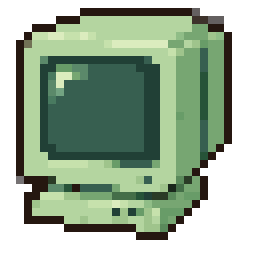

Inspected schema before preparing any image tensors.


In [8]:
source = None
schema_report = None
if not INFERENCE_ONLY:
    source = load_dataset(DATASET_ID, revision=DATASET_REVISION)
    schema_report = inspect_schema(source, image_column='image', caption_column='caption')
    display(source['train'][0]['image'].resize((256, 256), Image.Resampling.NEAREST))
    print('Inspected schema before preparing any image tensors.')

## 5. Frozen CLIP ViT-L/14 text features

We load only `CLIPTextModel`, not CLIP's image encoder. This checkpoint's text
hidden width is 768. Its tokenizer turns a caption into IDs; the frozen text
Transformer produces a sequence of token features. The U-Net learns to attend
to these features at 8×8 and 4×4 resolution.

CLIP stays in evaluation mode and has `requires_grad=False`. Its forward pass
uses `no_grad`; only the freshly initialized U-Net is optimized. We tokenize
captions once and encode each training microbatch on demand. Caching every
48×768 feature sequence for ~172k sprites would take roughly 12.7 GB even in
16-bit format, so we avoid that RAM cost.

For classifier-free guidance, the “no condition” is CLIP's encoding of the empty
string. We replace an entire caption's features and mask with that encoding in
10% of training examples. Padding tokens are excluded from cross-attention;
the empty string still has valid start/end tokens.

In [9]:
@torch.no_grad()
def encode_text_batch(text_encoder, ids, mask, device, use_bf16=True):
    # no_grad (not inference_mode): trainable cross-attention must save its inputs.
    with amp_context(device, use_bf16):
        hidden = text_encoder(input_ids=ids.to(device, non_blocking=True),
                              attention_mask=mask.to(device, non_blocking=True)).last_hidden_state
    return hidden.detach(), mask.to(device, dtype=torch.bool, non_blocking=True)


def train_one_batch(model, ema, optimizer, diffusion, images, ids, masks,
                    text_encoder, null_hidden, null_mask, micro_batch=64,
                    dropout=0.1, use_bf16=True, grad_clip=1.0):
    device = next(model.parameters()).device
    model.train()
    optimizer.zero_grad(set_to_none=True)
    batch_size, loss_sum = len(images), 0.0
    for start in range(0, batch_size, micro_batch):
        stop = min(start + micro_batch, batch_size)
        clean = images[start:stop].to(device, dtype=torch.float32, non_blocking=True) / 127.5 - 1
        clean = clean.contiguous(memory_format=torch.channels_last)
        hidden, mask = encode_text_batch(text_encoder, ids[start:stop], masks[start:stop], device, use_bf16)
        hidden, mask = conditioning_dropout(hidden, mask, null_hidden, null_mask, dropout)
        t = torch.randint(diffusion.timesteps, (len(clean),), device=device)
        noise = torch.randn_like(clean)
        noisy = diffusion.q_sample(clean, t, noise)
        with amp_context(device, use_bf16):
            prediction = model(noisy, t, hidden, mask)
        loss = F.mse_loss(prediction.float(), noise)
        if not torch.isfinite(loss):
            optimizer.zero_grad(set_to_none=True)
            raise FloatingPointError('Non-finite training loss; no optimizer update was applied.')
        (loss * ((stop - start) / batch_size)).backward()
        loss_sum += loss.detach().item() * (stop - start)
    norm = nn.utils.clip_grad_norm_(model.parameters(), grad_clip, error_if_nonfinite=True)
    optimizer.step()
    ema.update(model)
    return loss_sum / batch_size, float(norm)


@torch.no_grad()
def validation_loss(model, diffusion, loader, text_encoder, device, use_bf16=True, seed=31415):
    model.eval()
    gen = torch.Generator(device=device).manual_seed(seed)
    total, count = 0.0, 0
    for images, ids, masks in loader:
        clean = images.to(device, dtype=torch.float32, non_blocking=True) / 127.5 - 1
        hidden, mask = encode_text_batch(text_encoder, ids, masks, device, use_bf16)
        t = torch.randint(diffusion.timesteps, (len(clean),), generator=gen, device=device)
        noise = torch.randn(clean.shape, generator=gen, device=device)
        with amp_context(device, use_bf16):
            prediction = model(diffusion.q_sample(clean, t, noise), t, hidden, mask)
        loss = F.mse_loss(prediction.float(), noise)
        if not torch.isfinite(loss):
            raise FloatingPointError('Non-finite validation loss.')
        total += loss.item() * len(clean)
        count += len(clean)
    if not count:
        raise ValueError('Validation set is empty.')
    return total / count

In [10]:
tokenizer = CLIPTokenizerFast.from_pretrained(TEXT_ENCODER_ID, revision=TEXT_ENCODER_REVISION)
text_encoder = CLIPTextModel.from_pretrained(
    TEXT_ENCODER_ID, revision=TEXT_ENCODER_REVISION,
    dtype=torch.bfloat16 if USE_BF16 else torch.float32,
).to(device).eval().requires_grad_(False)
assert text_encoder.config.hidden_size == MODEL_CONFIG['text_dim']
assert MAX_TEXT_LENGTH <= text_encoder.config.max_position_embeddings

def encode_prompts(prompts):
    encoded = tokenizer(prompts, padding='max_length', truncation=True,
                        max_length=MAX_TEXT_LENGTH, return_tensors='pt')
    return encode_text_batch(text_encoder, encoded['input_ids'],
                             encoded['attention_mask'].bool(), device, USE_BF16)

null_hidden, null_mask = encode_prompts([''])
print('Frozen text encoder parameters:', f'{sum(p.numel() for p in text_encoder.parameters()):,}')
print('Null context shape:', tuple(null_hidden.shape), '| valid tokens:', int(null_mask.sum()))
assert not any(p.requires_grad for p in text_encoder.parameters())

tokenizer_config.json:   0%|          | 0.00/905 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/961k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.52k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.71GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

[transformers] CLIPTextModel LOAD REPORT from: openai/clip-vit-large-patch14
Key                                                            | Status     |  | 
---------------------------------------------------------------+------------+--+-
vision_model.encoder.layers.{0...23}.self_attn.k_proj.weight   | UNEXPECTED |  | 
vision_model.encoder.layers.{0...23}.self_attn.out_proj.weight | UNEXPECTED |  | 
vision_model.encoder.layers.{0...23}.mlp.fc2.bias              | UNEXPECTED |  | 
vision_model.encoder.layers.{0...23}.layer_norm2.bias          | UNEXPECTED |  | 
vision_model.encoder.layers.{0...23}.layer_norm2.weight        | UNEXPECTED |  | 
vision_model.encoder.layers.{0...23}.mlp.fc1.weight            | UNEXPECTED |  | 
vision_model.encoder.layers.{0...23}.layer_norm1.bias          | UNEXPECTED |  | 
vision_model.encoder.layers.{0...23}.self_attn.q_proj.weight   | UNEXPECTED |  | 
vision_model.encoder.layers.{0...23}.self_attn.v_proj.bias     | UNEXPECTED |  | 
vision_model.embeddin

Frozen text encoder parameters: 123,060,480
Null context shape: (1, 48, 768) | valid tokens: 2


## 6. Prepare uint8 pairs and reproducible splits

Images remain in memory-mapped uint8 files. Only a requested batch is converted
to float32. Token IDs and attention masks are cached; CLIP feature arrays are not.

Validation images are reserved first. Exact duplicate canonicalized RGBA images
are removed across the selected splits and within training. If `val` is absent,
the fallback assigns normalized-caption groups to train/validation by a stable
hash. This does not detect every near-duplicate or prove semantic independence.

The manifest records selected source rows, image hashes, source revisions,
preprocessing settings, and checksums. Resume rejects a different selected
dataset. Validation noise/timestep draws are fixed for comparisons across epochs.

In [11]:
data_manifest = None
train_data = val_data = None
if not INFERENCE_ONLY:
    DATA_CONFIG = dict(dataset_id=DATASET_ID, dataset_revision=DATASET_REVISION,
                       image_column='image', caption_column='caption', seed=SEED,
                       max_train_images=MAX_TRAIN_IMAGES, max_val_images=MAX_VAL_IMAGES,
                       reject_flags=REJECT_FLAGS, max_text_length=MAX_TEXT_LENGTH,
                       text_encoder_id=TEXT_ENCODER_ID, text_encoder_revision=TEXT_ENCODER_REVISION,
                       preprocessing='rgba32-transparent-white-dedup-v1')
    prepared_folder = WORK_ROOT / 'prepared' / digest(DATA_CONFIG)[:16]
    data_manifest = prepare_pairs(source, prepared_folder, DATA_CONFIG, tokenizer)
    train_data = SpritePairs(prepared_folder, 'train', data_manifest['splits']['train']['count'])
    val_data = SpritePairs(prepared_folder, 'val', data_manifest['splits']['val']['count'])
    del source
    source = None
    gc.collect()
    print('Actual train / validation:', len(train_data), '/', len(val_data))
    print('Dataset identity:', data_manifest['identity'])
    print('Training uint8 pixel storage: %.1f MiB' % (len(train_data) * 4 * 32 * 32 / 2**20))
    if len(train_data) < BATCH_SIZE:
        print('The final/only batch will be smaller than the configured logical batch.')

Prepare val:   0%|          | 0/720 [00:00<?, ?it/s]

val accepted: 512 | skipped: {'quality_flag': 143}


Prepare train:   0%|          | 0/172330 [00:00<?, ?it/s]

train accepted: 50000 | skipped: {'quality_flag': 5689}
Actual train / validation: 50000 / 512
Dataset identity: 1b69ffb516510ec15ca7ed1bf7beec7ac866535835d55ddd0f7e0fc4e98cbf1b
Training uint8 pixel storage: 195.3 MiB


## 7. U-Net architecture: the trainable image generator

| Resolution | Channels | Encoder | Decoder |
|---|---:|---|---|
| 32×32 | 64 | 2 residual blocks | 3 residual blocks with skips |
| 16×16 | 128 | 2 residual blocks | 3 residual blocks with skips |
| 8×8 | 192 | 2 residual + cross-attention blocks | 3 residual + cross-attention blocks |
| 4×4 | 256 | 2 residual + cross-attention blocks | 3 residual + cross-attention blocks |

The middle is residual → text cross-attention → residual. Stride-2 convolutions
downsample; nearest-neighbor upsampling followed by convolutions restores size.
Decoder blocks concatenate saved encoder features. A final convolution predicts
one noise value for each of the **4×32×32** input values. No sigmoid is applied
to predicted noise.

Each residual block uses GroupNorm, SiLU, two 3×3 convolutions, and a short path.
A sinusoidal timestep embedding becomes learned scale/shift vectors inside the
block. Cross-attention uses spatial queries and text keys/values with 64 values
per head, followed by a same-width feed-forward layer. A shared projection maps
the 768-dimensional frozen text features to 256 dimensions.

The default U-Net has **24,514,308 trainable parameters**; CLIP is counted
separately. The constructor and all denoising layers below are implemented here.

In [12]:
class TimeEmbedding(nn.Module):
    def __init__(self, base=64, dim=256):
        super().__init__()
        self.base = base
        self.mlp = nn.Sequential(nn.Linear(base, dim), nn.SiLU(), nn.Linear(dim, dim))

    def forward(self, t):
        half = self.base // 2
        frequencies = torch.exp(-math.log(10000) * torch.arange(half, device=t.device) / (half - 1))
        angles = t.float()[:, None] * frequencies[None, :]
        return self.mlp(torch.cat([angles.cos(), angles.sin()], dim=-1))


class ResBlock(nn.Module):
    """Pre-normalized residual convolutions; time controls scale and shift."""
    def __init__(self, cin, cout, time_dim=256, dropout=0.1):
        super().__init__()
        self.norm1 = nn.GroupNorm(8, cin)
        self.conv1 = nn.Conv2d(cin, cout, 3, padding=1)
        self.time = nn.Sequential(nn.SiLU(), nn.Linear(time_dim, 2 * cout))
        self.norm2 = nn.GroupNorm(8, cout)
        self.dropout = nn.Dropout(dropout)
        self.conv2 = nn.Conv2d(cout, cout, 3, padding=1)
        self.skip = nn.Identity() if cin == cout else nn.Conv2d(cin, cout, 1)

    def forward(self, x, time_emb):
        h = self.conv1(F.silu(self.norm1(x)))
        scale, shift = self.time(time_emb).chunk(2, dim=1)
        h = self.norm2(h) * (1 + scale[:, :, None, None]) + shift[:, :, None, None]
        h = self.conv2(self.dropout(F.silu(h)))
        return self.skip(x) + h


class CrossAttention(nn.Module):
    """Spatial queries attend to valid text tokens; no pretrained image layers."""
    def __init__(self, channels, context_dim=256, head_dim=64):
        super().__init__()
        assert channels % head_dim == 0
        self.heads = channels // head_dim
        self.norm = nn.GroupNorm(8, channels)
        self.q = nn.Linear(channels, channels, bias=False)
        self.k = nn.Linear(context_dim, channels, bias=False)
        self.v = nn.Linear(context_dim, channels, bias=False)
        self.out = nn.Linear(channels, channels)
        self.ff_norm = nn.LayerNorm(channels)
        self.ff = nn.Sequential(nn.Linear(channels, channels), nn.GELU(),
                                nn.Linear(channels, channels))

    def forward(self, x, context, mask):
        b, c, h, w = x.shape
        tokens = self.norm(x).flatten(2).transpose(1, 2)
        def heads(value):
            return value.reshape(b, -1, self.heads, c // self.heads).transpose(1, 2)
        q, k, v = heads(self.q(tokens)), heads(self.k(context)), heads(self.v(context))
        # In SDPA boolean masks, True means a token is allowed to participate.
        attended = F.scaled_dot_product_attention(q, k, v, attn_mask=mask[:, None, None, :])
        attended = attended.transpose(1, 2).reshape(b, h * w, c)
        tokens = x.flatten(2).transpose(1, 2) + self.out(attended)
        tokens = tokens + self.ff(self.ff_norm(tokens))
        return tokens.transpose(1, 2).reshape(b, c, h, w)


class ConditionedBlock(nn.Module):
    def __init__(self, cin, cout, time_dim, dropout, attention, context_dim=256, head_dim=64):
        super().__init__()
        self.res = ResBlock(cin, cout, time_dim, dropout)
        self.attn = CrossAttention(cout, context_dim, head_dim) if attention else None

    def forward(self, x, time_emb, context, mask):
        x = self.res(x, time_emb)
        return self.attn(x, context, mask) if self.attn is not None else x


class TextUNet(nn.Module):
    def __init__(self, in_channels=4, base=64, multipliers=(1, 2, 3, 4),
                 num_res_blocks=2, text_dim=768, context_dim=256,
                 dropout=0.1, gradient_checkpointing=False, head_dim=64):
        super().__init__()
        self.gradient_checkpointing = gradient_checkpointing
        self.time = TimeEmbedding(base, base * 4)
        self.text_projection = nn.Sequential(nn.LayerNorm(text_dim), nn.Linear(text_dim, context_dim))
        self.input = nn.Conv2d(in_channels, base, 3, padding=1)
        self.encoder = nn.ModuleList()
        self.downsamples = nn.ModuleList()
        skip_channels = [base]
        current, resolution = base, 32
        for level, multiplier in enumerate(multipliers):
            channels = base * multiplier
            blocks = nn.ModuleList()
            for _ in range(num_res_blocks):
                blocks.append(ConditionedBlock(current, channels, base * 4, dropout,
                                               resolution in (8, 4), context_dim, head_dim))
                current = channels
                skip_channels.append(current)
            self.encoder.append(blocks)
            if level < len(multipliers) - 1:
                self.downsamples.append(nn.Conv2d(current, current, 3, stride=2, padding=1))
                skip_channels.append(current)
                resolution //= 2
        self.middle1 = ConditionedBlock(current, current, base * 4, dropout, True, context_dim, head_dim)
        self.middle2 = ResBlock(current, current, base * 4, dropout)
        self.decoder = nn.ModuleList()
        self.upsamples = nn.ModuleList()
        for level in reversed(range(len(multipliers))):
            channels = base * multipliers[level]
            blocks = nn.ModuleList()
            for _ in range(num_res_blocks + 1):
                blocks.append(ConditionedBlock(current + skip_channels.pop(), channels, base * 4,
                                               dropout, resolution in (8, 4), context_dim, head_dim))
                current = channels
            self.decoder.append(blocks)
            if level > 0:
                self.upsamples.append(nn.Conv2d(current, current, 3, padding=1))
                resolution *= 2
        assert not skip_channels
        self.out_norm = nn.GroupNorm(8, current)
        self.output = nn.Conv2d(current, in_channels, 3, padding=1)
        # Start with an almost uninformative prediction; gradients reach all layers.
        nn.init.normal_(self.output.weight, std=0.01)
        nn.init.zeros_(self.output.bias)

    def run_block(self, block, *args):
        if self.gradient_checkpointing and self.training and torch.is_grad_enabled():
            return checkpoint(block, *args, use_reentrant=False)
        return block(*args)

    def forward(self, x, timesteps, text_hidden, text_mask):
        time_emb = self.time(timesteps)
        context = self.text_projection(text_hidden)
        h = self.input(x)
        skips = [h]
        for level, blocks in enumerate(self.encoder):
            for block in blocks:
                h = self.run_block(block, h, time_emb, context, text_mask)
                skips.append(h)
            if level < len(self.downsamples):
                h = self.downsamples[level](h)
                skips.append(h)
        h = self.run_block(self.middle1, h, time_emb, context, text_mask)
        h = self.run_block(self.middle2, h, time_emb)
        for level, blocks in enumerate(self.decoder):
            for block in blocks:
                h = torch.cat([h, skips.pop()], dim=1)
                h = self.run_block(block, h, time_emb, context, text_mask)
            if level < len(self.upsamples):
                h = self.upsamples[level](F.interpolate(h, scale_factor=2, mode='nearest'))
        return self.output(F.silu(self.out_norm(h)))


class EMA:
    def __init__(self, model, decay=0.9999):
        self.model = copy.deepcopy(model).eval().requires_grad_(False)
        self.decay = decay
        self.updates = 0

    @torch.no_grad()
    def update(self, model):
        self.updates += 1
        # Warm up averaging so a young EMA does not retain initial random weights.
        decay = min(self.decay, (1 + self.updates) / (10 + self.updates))
        for target, source in zip(self.model.parameters(), model.parameters()):
            target.lerp_(source.detach(), 1 - decay)
        for target, source in zip(self.model.buffers(), model.buffers()):
            target.copy_(source)

In [13]:
seed_everything(SEED)
model = TextUNet(**MODEL_CONFIG, gradient_checkpointing=GRADIENT_CHECKPOINTING).to(device)
model = model.to(memory_format=torch.channels_last)
parameter_count = sum(p.numel() for p in model.parameters())
print('Trainable U-Net parameters:', f'{parameter_count:,}')
if MODEL_CONFIG == dict(in_channels=4, base=64, multipliers=[1, 2, 3, 4],
                         num_res_blocks=2, text_dim=768, context_dim=256, dropout=0.1, head_dim=64):
    assert parameter_count == 24_514_308
assert 15_000_000 <= parameter_count <= 25_000_000, 'Architecture outside requested 15–25M range.'
ema = EMA(model, EMA_DECAY)
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY,
                             betas=(0.9, 0.999), fused=(device.type == 'cuda'))
print('Parameter memory only:', round(parameter_count * 4 / 2**20, 1), 'MiB; training also needs EMA, Adam state and activations.')

Trainable U-Net parameters: 24,514,308
Parameter memory only: 93.5 MiB; training also needs EMA, Adam state and activations.


## 8. Diffusion equations and classifier-free guidance

The forward process adds Gaussian noise to a clean sprite $x_0$:

$$x_t=\sqrt{\bar\alpha_t}x_0+\sqrt{1-\bar\alpha_t}\epsilon,
\qquad \epsilon\sim\mathcal N(0,I).$$

The cosine schedule uses
$f(t)=\cos^2(\frac{t/T+s}{1+s}\frac\pi2)$, $s=0.008$,
$\bar\alpha=f(t)/f(0)$, and
$\beta_t=\min(1-\bar\alpha_{t+1}/\bar\alpha_t,0.999)$.
Arrays use zero-based indices: index 0 is the first slightly corrupted level;
index 999 is the most corrupted. We store the cumulative product of the actual
clipped discrete alphas. Training samples a timestep independently per image.

The network predicts noise, minimizing
$$\mathcal L=\mathbb E\big[\|\epsilon-\epsilon_\theta(x_t,t,c)\|^2\big].$$
Pixel/channel/batch averaging is explicit in `F.mse_loss`. This is denoising
loss; it does not certify prompt correctness or pixel-art quality.

At generation, classifier-free guidance combines two predictions:
$$\hat\epsilon=\epsilon_\theta(x_t,t,\varnothing)
+w\,[\epsilon_\theta(x_t,t,c)-\epsilon_\theta(x_t,t,\varnothing)].$$
Here $w=1$ gives the ordinary conditional prediction, $w=0$ is unconditional,
and larger values increase guidance, sometimes at the cost of artifacts/diversity.

In [14]:
class Diffusion:
    def __init__(self, timesteps=1000, device='cpu', cosine_s=0.008):
        self.timesteps = timesteps
        self.device = torch.device(device)
        grid = torch.linspace(0, timesteps, timesteps + 1, dtype=torch.float64)
        f = torch.cos(((grid / timesteps + cosine_s) / (1 + cosine_s)) * math.pi / 2).square()
        cumulative = f / f[0]
        self.betas = (1 - cumulative[1:] / cumulative[:-1]).clamp(max=0.999).float().to(device)
        self.alphas = 1 - self.betas
        self.alpha_bars = self.alphas.cumprod(0)

    @staticmethod
    def extract(array, t, ndim=4):
        return array[t].reshape(-1, *([1] * (ndim - 1)))

    def q_sample(self, clean, t, noise):
        a = self.extract(self.alpha_bars, t)
        return a.sqrt() * clean.float() + (1 - a).sqrt() * noise.float()

    def predict_clean(self, noisy, t, predicted_noise):
        a = self.extract(self.alpha_bars, t)
        return (noisy.float() - (1 - a).sqrt() * predicted_noise.float()) / a.sqrt()

    def ddpm_step(self, noisy, t, predicted_noise, noise, previous_t=None):
        """An ancestral DDPM step on the full or correctly respaced schedule."""
        previous_t = t - 1 if previous_t is None else previous_t
        a = self.extract(self.alpha_bars, t)
        previous = self.extract(self.alpha_bars, previous_t.clamp(min=0))
        previous = torch.where((previous_t < 0)[:, None, None, None], torch.ones_like(previous), previous)
        alpha = a / previous
        beta = 1 - alpha
        clean = self.predict_clean(noisy, t, predicted_noise).clamp(-1, 1)
        mean = beta * previous.sqrt() / (1 - a) * clean
        mean = mean + (1 - previous) * alpha.sqrt() / (1 - a) * noisy
        variance = beta * (1 - previous) / (1 - a)
        nonzero = (previous_t >= 0)[:, None, None, None]
        return mean + nonzero * variance.clamp(min=0).sqrt() * noise

    def ddim_step(self, noisy, t, previous_t, predicted_noise, noise, eta=0.0):
        """A possibly non-adjacent DDIM step; previous_t = -1 means clean data."""
        if not 0 <= eta <= 1:
            raise ValueError('DDIM eta must be between 0 and 1.')
        a = self.extract(self.alpha_bars, t)
        previous = self.extract(self.alpha_bars, previous_t.clamp(min=0))
        previous = torch.where((previous_t < 0)[:, None, None, None], torch.ones_like(previous), previous)
        clean = self.predict_clean(noisy, t, predicted_noise).clamp(-1, 1)
        # Recompute epsilon after clipping x0 so the DDIM direction is consistent.
        corrected_noise = (noisy - a.sqrt() * clean) / (1 - a).sqrt()
        sigma = eta * (((1 - previous) / (1 - a)) * (1 - a / previous)).clamp(min=0).sqrt()
        direction = (1 - previous - sigma.square()).clamp(min=0).sqrt() * corrected_noise
        return previous.sqrt() * clean + direction + sigma * noise


def conditioning_dropout(hidden, mask, null_hidden, null_mask, probability=0.1):
    drop = torch.rand(hidden.shape[0], device=hidden.device) < probability
    hidden = torch.where(drop[:, None, None], null_hidden.expand_as(hidden), hidden)
    mask = torch.where(drop[:, None], null_mask.expand_as(mask), mask)
    return hidden, mask


@torch.no_grad()
def sample_images(model, diffusion, hidden, mask, null_hidden, null_mask,
                  sampler='ddim', steps=50, guidance=4.0, seed=42,
                  eta=0.0, channels=4, use_bf16=True, progress=False, frames=9):
    """Both samplers support a respaced grid; DDPM recomputes its effective betas."""
    if sampler not in ('ddpm', 'ddim'):
        raise ValueError('sampler must be ddpm or ddim')
    if not 2 <= steps <= diffusion.timesteps:
        raise ValueError('steps must be between 2 and the number of diffusion timesteps.')
    was_training = model.training
    model.eval()
    device = next(model.parameters()).device
    gen = torch.Generator(device=device).manual_seed(seed)
    b = hidden.shape[0]
    x = torch.randn((b, channels, 32, 32), generator=gen, device=device)
    indices = torch.linspace(diffusion.timesteps - 1, 0, steps, device=device).round().long()
    record_at = set(np.linspace(0, steps - 1, min(frames, steps)).round().astype(int).tolist())
    trajectory = [('initial noise', x[:1].detach().cpu())]
    iterator = enumerate(indices.tolist())
    if progress:
        from tqdm.auto import tqdm
        iterator = tqdm(iterator, total=steps, desc=f'{sampler.upper()} sampling')
    try:
        for i, index in iterator:
            t = torch.full((b,), index, device=device, dtype=torch.long)
            with amp_context(device, use_bf16):
                if guidance == 1.0:
                    predicted = model(x, t, hidden, mask)
                else:
                    # Sequential CFG halves the peak batch size versus concatenating.
                    unconditioned = model(x, t, null_hidden.expand(b, -1, -1), null_mask.expand(b, -1))
                    conditioned = model(x, t, hidden, mask)
                    predicted = unconditioned + guidance * (conditioned - unconditioned)
            fresh_noise = torch.randn(x.shape, device=device, generator=gen)
            prev = indices[i + 1].item() if i + 1 < steps else -1
            previous_t = torch.full_like(t, prev)
            if sampler == 'ddpm':
                x = diffusion.ddpm_step(x, t, predicted.float(), fresh_noise, previous_t)
            else:
                x = diffusion.ddim_step(x, t, previous_t, predicted.float(), fresh_noise, eta)
            if not torch.isfinite(x).all():
                raise FloatingPointError(f'Non-finite sample at timestep {index}.')
            if i in record_at:
                trajectory.append((f'after t={index}', x[:1].detach().cpu()))
    finally:
        model.train(was_training)
    return x.clamp(-1, 1).cpu(), trajectory

In [15]:
diffusion = Diffusion(**DIFFUSION_CONFIG, device=device)
assert torch.isfinite(diffusion.alpha_bars).all()
assert torch.all(diffusion.alpha_bars[1:] < diffusion.alpha_bars[:-1])
print('Timesteps:', diffusion.timesteps, '| first/last alpha_bar:',
      diffusion.alpha_bars[0].item(), diffusion.alpha_bars[-1].item())

Timesteps: 1000 | first/last alpha_bar: 0.9999586939811707 2.428733658632609e-09


## 9. Synthetic smoke test and L4 memory probe

Before full training, this checks output shapes, finite loss/gradients, noise
reconstruction, conditioning dropout, and both samplers. It does **not** establish
generation quality. The smoke test computes gradients without updating weights.

The optional L4 probe attempts the requested microbatch and halves it on CUDA
OOM. It reserves room for Adam's two FP32 moment arrays before probing. BF16
autocast uses FP32 master weights, loss, and diffusion arithmetic; BF16 does not
need an FP16 gradient scaler. RNG states are restored after these tests so a
resumed training RNG stream is not changed by testing.

In [16]:
if RUN_SMOKE_TEST and not INFERENCE_ONLY:
    smoke_rng = capture_rng()
    try:
        model.train()
        x0 = torch.rand(2, 4, 32, 32, device=device) * 2 - 1
        eps = torch.randn_like(x0)
        t = torch.tensor([10, 700], device=device)
        xt = diffusion.q_sample(x0, t, eps)
        reconstructed = diffusion.predict_clean(xt, t, eps)
        torch.testing.assert_close(reconstructed, x0, atol=2e-5, rtol=2e-5)
        h, mask = encode_prompts(['a red sword', 'a blue potion'])
        dropped_h, dropped_mask = conditioning_dropout(h, mask, null_hidden, null_mask, 1.0)
        torch.testing.assert_close(dropped_h, null_hidden.expand_as(h))
        assert torch.equal(dropped_mask, null_mask.expand_as(mask))
        with amp_context(device, USE_BF16):
            prediction = model(xt, t, h, mask)
        assert prediction.shape == x0.shape
        loss = F.mse_loss(prediction.float(), eps)
        loss.backward()
        assert all(torch.isfinite(p.grad).all() for p in model.parameters() if p.grad is not None)
        model.zero_grad(set_to_none=True)
        for method in ('ddpm', 'ddim'):
            result, frames = sample_images(model, diffusion, h[:1], mask[:1], null_hidden, null_mask,
                                           sampler=method, steps=3, guidance=1, use_bf16=USE_BF16)
            assert result.shape == (1, 4, 32, 32) and torch.isfinite(result).all()
        assert all(p.grad is None for p in text_encoder.parameters())
        print('Smoke test passed: q(x_t), reconstruction, CFG dropout, U-Net backward, DDPM and DDIM.')
    finally:
        model.zero_grad(set_to_none=True)
        restore_rng(smoke_rng)
        for name in ('x0', 'eps', 'xt', 'prediction', 'loss', 'h', 'mask', 'result', 'frames'):
            globals().pop(name, None)
        gc.collect()
        if device.type == 'cuda':
            torch.cuda.empty_cache()

def probe_microbatch(size):
    # CLIP and EMA already reside on the GPU during this probe.
    model.train()
    reserve = torch.empty(2 * parameter_count, device=device, dtype=torch.float32)
    x = torch.randn(size, 4, 32, 32, device=device).contiguous(memory_format=torch.channels_last)
    h = torch.randn(size, MAX_TEXT_LENGTH, MODEL_CONFIG['text_dim'], device=device)
    mask = torch.ones(size, MAX_TEXT_LENGTH, device=device, dtype=torch.bool)
    t = torch.full((size,), 500, device=device, dtype=torch.long)
    with amp_context(device, USE_BF16):
        prediction = model(x, t, h, mask)
    F.mse_loss(prediction.float(), x).backward()
    torch.cuda.synchronize()
    return torch.cuda.max_memory_allocated() / 2**30

if RUN_VRAM_PROBE and device.type == 'cuda' and not INFERENCE_ONLY:
    probe_rng = capture_rng()
    MICRO_BATCH_SIZE = min(MICRO_BATCH_SIZE, BATCH_SIZE)
    try:
        while True:
            torch.cuda.reset_peak_memory_stats()
            try:
                peak = probe_microbatch(MICRO_BATCH_SIZE)
                print(f'Microbatch {MICRO_BATCH_SIZE} passed; probe peak {peak:.2f} GiB.')
                break
            except torch.cuda.OutOfMemoryError:
                model.zero_grad(set_to_none=True)
                gc.collect()
                torch.cuda.empty_cache()
                if MICRO_BATCH_SIZE == 1:
                    raise RuntimeError('Microbatch 1 cannot fit. Enable GRADIENT_CHECKPOINTING or check other GPU allocations.')
                MICRO_BATCH_SIZE = max(1, MICRO_BATCH_SIZE // 2)
                print('CUDA OOM during probe; trying microbatch', MICRO_BATCH_SIZE)
            finally:
                model.zero_grad(set_to_none=True)
    finally:
        restore_rng(probe_rng)
        gc.collect()
        torch.cuda.empty_cache()
print('Logical / microbatch:', BATCH_SIZE, '/', MICRO_BATCH_SIZE)

Smoke test passed: q(x_t), reconstruction, CFG dropout, U-Net backward, DDPM and DDIM.
Microbatch 64 passed; probe peak 2.20 GiB.
Logical / microbatch: 64 / 64


## 10. Initialize or restore the training state

Compatibility includes the dataset identity, U-Net/diffusion configuration,
CLIP revision, logical batch size, Adam settings, loss dropout, and EMA settings.
You may increase total `EPOCHS` or change logging/checkpoint intervals when
resuming. If changing a protected setting, choose a new run name.

The next cell restores the cursor and RNG after model construction. A deterministic
per-epoch permutation reconstructs the remaining batches, even with prefetching.
There are no random image augmentations. Exact bitwise reproduction across GPU
types, PyTorch versions, or changed microbatch sizes is not guaranteed.

Save checkpoints contain only tensors and Python primitives, allowing
`torch.load(..., weights_only=True)`. The Bucket retains two rotating resume
payloads rather than a permanent checkpoint for every epoch.

In [17]:
provenance = dict(dataset_id=DATASET_ID, dataset_revision=DATASET_REVISION,
                  text_encoder_id=TEXT_ENCODER_ID, text_encoder_revision=TEXT_ENCODER_REVISION,
                  max_text_length=MAX_TEXT_LENGTH,
                  versions={p: package_metadata.version(p) for p in
                            ('torch', 'numpy', 'transformers', 'datasets', 'huggingface_hub')})
state = new_training_state()
best_ema = None
run_signature = None
if not INFERENCE_ONLY:
    protected = dict(model=MODEL_CONFIG, diffusion=DIFFUSION_CONFIG,
                     data_identity=data_manifest['identity'], batch_size=BATCH_SIZE, val_batch_size=VAL_BATCH_SIZE,
                     lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY,
                     adam_betas=[0.9, 0.999], condition_dropout=CONDITION_DROPOUT,
                     ema_decay=EMA_DECAY, grad_clip=GRAD_CLIP,
                     precision='bf16' if USE_BF16 else 'fp32', code_version='pixelart-ddpm-v1')
    run_signature = digest(protected)
    if boot_checkpoint is not None:
        state, best_ema = restore_training(boot_checkpoint, model, ema, optimizer, run_signature)
        print('Resumed: epoch index', state['epoch'], '| next batch', state['next_batch'],
              '| updates', state['global_step'])
    else:
        print('Fresh image model; no pretrained image-generation weights loaded.')
    total_batches = math.ceil(len(train_data) / BATCH_SIZE)
    if not 0 <= state['next_batch'] <= total_batches:
        raise ValueError('Invalid saved batch cursor.')
    print('Updates / epoch:', total_batches, '| target total epochs:', EPOCHS)
else:
    ema.model.load_state_dict(boot_checkpoint['ema'])
    ema.updates = boot_checkpoint['ema_updates']
    state = copy.deepcopy(boot_checkpoint['state'])
    best_ema = boot_checkpoint['best_ema']
    print('Inference-only: skipped dataset download and training-state initialization.')

def save_checkpoint():
    payload = build_payload(model, ema, optimizer, state, best_ema, MODEL_CONFIG,
                            DIFFUSION_CONFIG, run_signature, data_manifest, provenance)
    atomic_torch_save(payload, OUTPUT_DIR / 'last-local.pt')
    if store is not None:
        store.save(payload)
    del payload

# Release the boot snapshot after its state has been restored (saves host RAM).
boot_checkpoint = None
gc.collect()

Fresh image model; no pretrained image-generation weights loaded.
Updates / epoch: 782 | target total epochs: 50


150

## 11. Train (this cell performs the updates)

For each logical batch:

1. Convert uint8 RGBA to [-1,1], and run frozen CLIP on its captions.
2. Drop whole caption conditioning with probability 0.10.
3. Draw a random timestep and Gaussian noise for each example.
4. Predict noise and calculate MSE in float32.
5. Backpropagate weighted microbatch losses, clip gradients, update AdamW, then EMA.

BF16, channels-last convolutions, fused AdamW on CUDA, SDPA cross-attention,
pinned CPU batches, and on-demand text encoding target the L4. Validation uses
the **EMA** model without conditioning dropout or classifier-free guidance.
The best EMA is selected by fixed-draw validation noise MSE.

Snapshots are committed every `CHECKPOINT_EVERY` updates and after each epoch.
On a caught keyboard interrupt, the notebook rolls back to the last complete
local checkpoint before uploading it. This avoids saving partially updated
optimizer state. Work since that snapshot is discarded. A sudden runtime termination cannot run
cleanup; resume from the last successful remote commit. Re-executing this cell
continues from the current cursor rather than restarting the epoch.

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...p-l14-full-v1/resume-b.pt:  11%|#1        | 55.5MB /  495MB            

Validating                    :           |   0%            

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

... (121 outputs left out)

New Data Upload               : |          |  0.00B /  0.00B            

  ...ull-v1/latest-upload.json: 100%|##########|   174B /   174B            

Validating                    :           |   0%            

Bucket committed step 35190: Tobyz11/pixelart-text-ddpm/rgba-clip-l14-full-v1


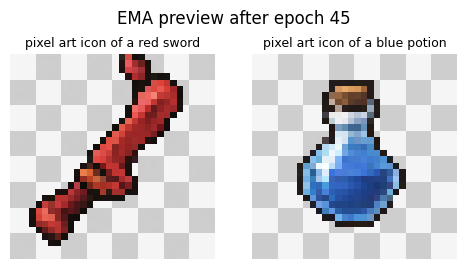

Epoch 46/50:   0%|          | 0/782 [00:00<?, ?it/s]

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...p-l14-full-v1/resume-b.pt:   0%|          | 56.2kB /  495MB            

Validating                    :           |   0%            

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

... (112 outputs left out)

New Data Upload               : |          |  0.00B /  0.00B            

  ...ull-v1/latest-upload.json: 100%|##########|   174B /   174B            

Validating                    :           |   0%            

Bucket committed step 39100: Tobyz11/pixelart-text-ddpm/rgba-clip-l14-full-v1


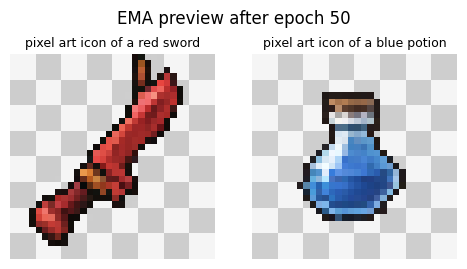

Training completed: 39100 optimizer updates.


In [18]:
def run_training():
    global best_ema, state
    if INFERENCE_ONLY:
        print('INFERENCE_ONLY=True: training skipped.')
        return
    if state['epoch'] >= EPOCHS:
        print('Target epochs already completed. Increase EPOCHS to continue.')
        return
    if MAX_STEPS is not None and state['global_step'] >= MAX_STEPS:
        print('MAX_STEPS already reached. Increase it or set None to continue.')
        return
    # Validation uses a dedicated generator so loader setup does not consume training RNG.
    val_loader = DataLoader(val_data, batch_size=VAL_BATCH_SIZE, shuffle=False,
                            num_workers=NUM_WORKERS, pin_memory=device.type == 'cuda',
                            generator=torch.Generator().manual_seed(SEED + 200000))
    interrupted = False
    # A valid rollback point exists even if the first optimizer update is interrupted.
    save_checkpoint()
    try:
        while state['epoch'] < EPOCHS:
            epoch = state['epoch']
            loader = make_train_loader(train_data, BATCH_SIZE, SEED, epoch, state['next_batch'],
                                       NUM_WORKERS, device.type == 'cuda')
            bar = tqdm(loader, desc=f'Epoch {epoch + 1}/{EPOCHS}', leave=True)
            for images, ids, masks in bar:
                loss, norm = train_one_batch(model, ema, optimizer, diffusion, images, ids, masks,
                                             text_encoder, null_hidden, null_mask,
                                             MICRO_BATCH_SIZE, CONDITION_DROPOUT, USE_BF16, GRAD_CLIP)
                state['global_step'] += 1
                state['next_batch'] += 1
                state['epoch_loss_sum'] += loss * len(images)
                state['epoch_images'] += len(images)
                bar.set_postfix(mse=f'{loss:.4f}', step=state['global_step'])
                if state['global_step'] % LOG_EVERY == 0:
                    state['step_history'].append(dict(step=state['global_step'], loss=loss, grad_norm=norm))
                if state['global_step'] % CHECKPOINT_EVERY == 0:
                    save_checkpoint()
                if MAX_STEPS is not None and state['global_step'] >= MAX_STEPS:
                    bar.close()
                    # Record a fixed-draw EMA validation for the debug stop as well.
                    val = validation_loss(ema.model, diffusion, val_loader, text_encoder, device, USE_BF16)
                    if val < state['best_val']:
                        state['best_val'] = val
                        best_ema = cpu_tree(ema.model.state_dict())
                    save_checkpoint()
                    print(f'MAX_STEPS stop at {state["global_step"]}; EMA validation MSE: {val:.5f}.')
                    return
            train_mse = state['epoch_loss_sum'] / max(1, state['epoch_images'])
            val_mse = validation_loss(ema.model, diffusion, val_loader, text_encoder, device, USE_BF16)
            state['history'].append(dict(epoch=epoch + 1, step=state['global_step'],
                                         train_mse=train_mse, ema_val_mse=val_mse))
            if val_mse < state['best_val']:
                state['best_val'] = val_mse
                best_ema = cpu_tree(ema.model.state_dict())
            state.update(epoch=epoch + 1, next_batch=0, epoch_loss_sum=0.0, epoch_images=0)
            print(f'Epoch {epoch + 1}: training MSE={train_mse:.5f}; EMA validation={val_mse:.5f}')
            save_checkpoint()
            if (epoch + 1) % PREVIEW_EVERY_EPOCHS == 0:
                h, mask = encode_prompts(PROMPTS[:2])
                preview, _ = sample_images(ema.model, diffusion, h, mask, null_hidden, null_mask,
                                            steps=50, guidance=GUIDANCE_SCALE, seed=GENERATION_SEED,
                                            use_bf16=USE_BF16)
                show_sprites(preview, PROMPTS[:2], columns=2, title=f'EMA preview after epoch {epoch + 1}')
    except KeyboardInterrupt:
        interrupted = True
        print('Interrupted. Rolling back unfinished work to the last complete local snapshot...')
        optimizer.zero_grad(set_to_none=True)
        rollback = torch.load(OUTPUT_DIR / 'last-local.pt', map_location='cpu', weights_only=True)
        state, best_ema = restore_training(rollback, model, ema, optimizer, run_signature)
        del rollback
        save_checkpoint()
    if not interrupted:
        print('Training completed:', state['global_step'], 'optimizer updates.')

# Plot/display functions are defined here so optional training previews work.
def tensor_to_rgba(image, threshold_alpha=False):
    rgba = ((image.detach().cpu().float().clamp(-1, 1) + 1) * 127.5).round().byte()
    rgba = rgba.permute(1, 2, 0).numpy().copy()
    if threshold_alpha:
        rgba[:, :, 3] = np.where(rgba[:, :, 3] >= 128, 255, 0)
        rgba[rgba[:, :, 3] == 0, :3] = 255
    return Image.fromarray(rgba)


def checkerboard(image, scale=6):
    rgba = image.convert('RGBA')
    yy, xx = np.indices((rgba.height, rgba.width))
    values = np.where((xx // 4 + yy // 4) % 2, 205, 245).astype(np.uint8)
    bg = Image.fromarray(np.repeat(values[:, :, None], 3, axis=2)).convert('RGBA')
    result = Image.alpha_composite(bg, rgba).convert('RGB')
    return result.resize((rgba.width * scale, rgba.height * scale), Image.Resampling.NEAREST)


def show_sprites(images, labels=None, columns=4, threshold_alpha=False, title=None):
    import matplotlib.pyplot as plt
    rows = math.ceil(len(images) / columns)
    fig, axes = plt.subplots(rows, columns, figsize=(columns * 2.5, rows * 2.7), squeeze=False)
    for ax in axes.flat:
        ax.axis('off')
    for i, image in enumerate(images):
        axes.flat[i].imshow(checkerboard(tensor_to_rgba(image, threshold_alpha)), interpolation='nearest')
        if labels:
            axes.flat[i].set_title(labels[i], fontsize=9, wrap=True)
    if title:
        fig.suptitle(title)
    plt.tight_layout()
    plt.show()

run_training()

## 12. Inspect training and validation curves

Step losses are noisy because the timesteps, noise arrays, and examples change.
Epoch validation uses fixed noise/timestep draws and the same EMA model type.
It measures denoising, not prompt fidelity. Training and validation also differ
because training uses caption dropout and the raw weights.

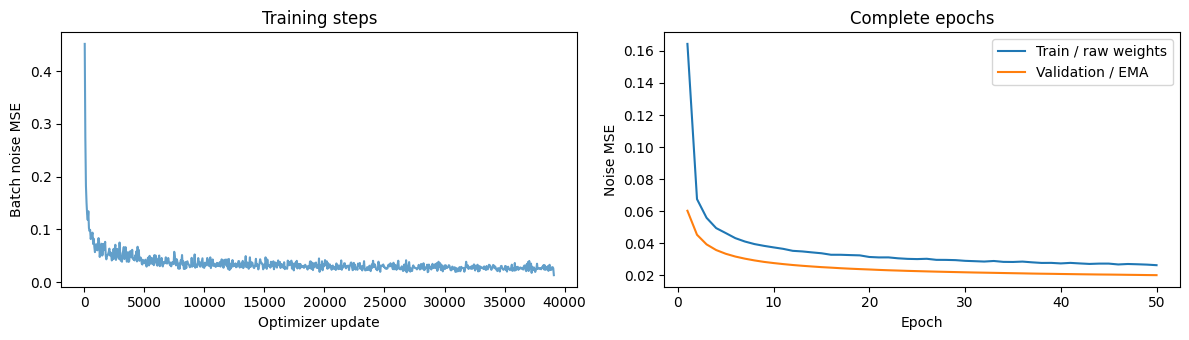

Completed updates: 39100 | best EMA validation MSE: 0.0201795146567747


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
if state['step_history']:
    axes[0].plot([r['step'] for r in state['step_history']],
                 [r['loss'] for r in state['step_history']], alpha=0.7)
axes[0].set(xlabel='Optimizer update', ylabel='Batch noise MSE', title='Training steps')
if state['history']:
    axes[1].plot([r['epoch'] for r in state['history']],
                 [r['train_mse'] for r in state['history']], label='Train / raw weights')
    axes[1].plot([r['epoch'] for r in state['history']],
                 [r['ema_val_mse'] for r in state['history']], label='Validation / EMA')
    axes[1].legend()
else:
    axes[1].text(.5, .5, 'No complete epochs yet (normal in debug mode).', ha='center', transform=axes[1].transAxes)
axes[1].set(xlabel='Epoch', ylabel='Noise MSE', title='Complete epochs')
plt.tight_layout()
plt.show()
print('Completed updates:', state['global_step'], '| best EMA validation MSE:', state['best_val'])

## 13. Generate: DDPM and DDIM, with custom prompts

Training has learned $\epsilon_\theta$. Both samplers first estimate clean data:

$$\hat x_0=(x_t-\sqrt{1-\bar\alpha_t}\,\hat\epsilon)/\sqrt{\bar\alpha_t}.$$

We clip that estimate to [-1,1]. For a reverse step from level $t$ to level $s<t$,
set $a=\bar\alpha_t$, $b=\bar\alpha_s$ (and $b=1$ for the final clean output).

**Ancestral DDPM:** recompute $\alpha'=a/b$, $\beta'=1-\alpha'$, then
$$\mu=\frac{\sqrt b\,\beta'}{1-a}\hat x_0
+\frac{\sqrt{\alpha'}(1-b)}{1-a}x_t,\qquad
\tilde\beta=\frac{1-b}{1-a}\beta'.$$
Sample $x_s=\mu+\sqrt{\tilde\beta}\,z$. At the final clean output the variance
is zero. With 1,000 steps this is the original adjacent DDPM chain; with 50 steps
it is a correctly **respaced ancestral schedule**, not unchanged coefficients
inside a loop that simply skips indices.

**DDIM:**
$$\sigma=\eta\sqrt{\frac{1-b}{1-a}\left(1-\frac ab\right)},\qquad
x_s=\sqrt b\,\hat x_0+\sqrt{1-b-\sigma^2}\,\hat\epsilon_{\rm corrected}+\sigma z.$$
We recompute $\hat\epsilon_{\rm corrected}$ from the clipped clean estimate.
`eta=0` gives deterministic DDIM given the initial noise. Both methods default
to 50 steps here; compare to DDPM at 1,000 steps when evaluating a trained run.

Use the same seed to compare checkpoints and guidance settings. Change the seed
to explore variation. Start around guidance 2–5 and inspect actual results.

Using the best validated EMA; noise MSE: 0.0201795146567747


DDIM sampling:   0%|          | 0/50 [00:00<?, ?it/s]

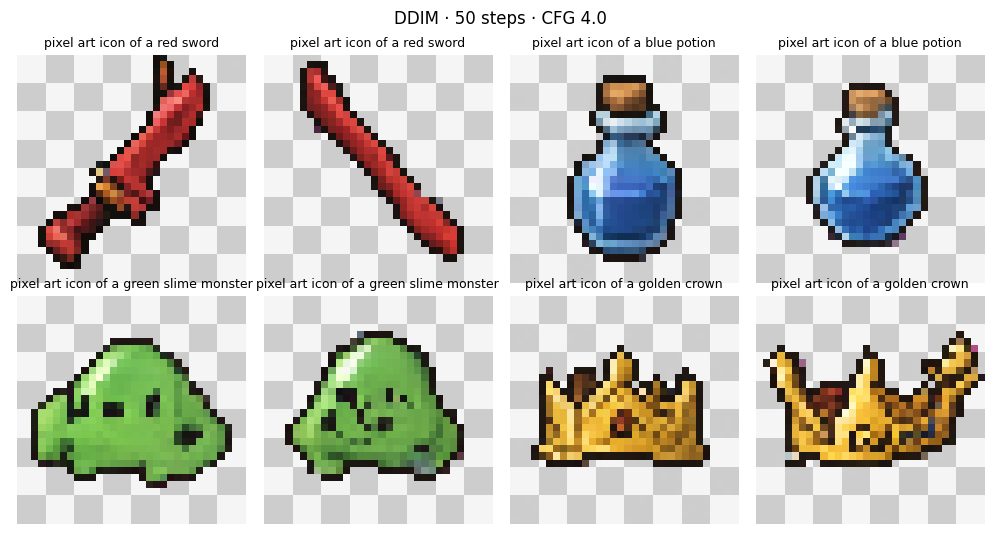

Unthresholded RGBA outputs; checkerboard is for display only.


In [ ]:
GENERATION_WEIGHTS = 'best'      # 'best' or 'latest'; selection never alters the live training EMA.
if GENERATION_WEIGHTS == 'best' and best_ema is not None:
    generation_state = best_ema
    print('Using the best validated EMA; noise MSE:', state['best_val'])
elif GENERATION_WEIGHTS in ('best', 'latest'):
    generation_state = ema.model.state_dict()
    print('Using the current EMA (no validated best available yet).')
else:
    raise ValueError('GENERATION_WEIGHTS must be best or latest.')

generation_model = TextUNet(**MODEL_CONFIG).to(device).eval().requires_grad_(False)
generation_model.load_state_dict(generation_state)
generation_model.to(memory_format=torch.channels_last)

# Edit these values and rerun this cell to try your own prompts.
SAMPLER = 'ddim'                # 'ddpm' also supports 50 respaced steps.
SAMPLING_STEPS = 50             # Set 1000 for full DDPM.
GUIDANCE_SCALE = 4.0
GENERATION_SEED = 123
DDIM_ETA = 0.0
PROMPTS = ['pixel art icon of a red sword', 'pixel art icon of a blue potion',
           'pixel art icon of a green slime monster', 'pixel art icon of a golden crown']
SAMPLES_PER_PROMPT = 2

expanded_prompts = [p for p in PROMPTS for _ in range(SAMPLES_PER_PROMPT)]
if not expanded_prompts or any(not p.strip() for p in expanded_prompts):
    raise ValueError('Provide at least one nonempty prompt and SAMPLES_PER_PROMPT >= 1.')
prompt_hidden, prompt_mask = encode_prompts(expanded_prompts)
generated, reverse_frames = sample_images(
    generation_model, diffusion, prompt_hidden, prompt_mask, null_hidden, null_mask,
    sampler=SAMPLER, steps=SAMPLING_STEPS, guidance=GUIDANCE_SCALE, seed=GENERATION_SEED,
    eta=DDIM_ETA, use_bf16=USE_BF16, progress=True,
)
show_sprites(generated, expanded_prompts, columns=4, title=f'{SAMPLER.upper()} · {SAMPLING_STEPS} steps · CFG {GUIDANCE_SCALE}')
print('Unthresholded RGBA outputs; checkerboard is for display only.')

DDIM sampling:   0%|          | 0/50 [00:00<?, ?it/s]

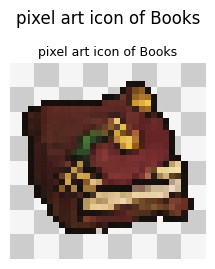

In [ ]:
PROMPT = "pixel art icon of Books"
SEED = 123

# Use the best validated EMA if available.
weights = best_ema if best_ema is not None else ema.model.state_dict()
generation_model = TextUNet(**MODEL_CONFIG).to(device).eval().requires_grad_(False)
generation_model.load_state_dict(weights)
generation_model.to(memory_format=torch.channels_last)

prompt_hidden, prompt_mask = encode_prompts([PROMPT])

generated, _ = sample_images(
    generation_model, diffusion,
    prompt_hidden, prompt_mask, null_hidden, null_mask,
    sampler="ddim",
    steps=50,
    guidance=4.0,
    seed=SEED,
    eta=0.0,
    use_bf16=USE_BF16,
    progress=True,
)

show_sprites(generated, [PROMPT], columns=1, title=PROMPT)

## 14. Visualize forward noise and real reverse denoising

The forward plot uses one clean sprite and one fixed noise draw at several
levels. The reverse plot uses frames actually recorded by the sampler above,
not a crossfade to a known target. We show RGB and alpha separately because a
noisy alpha channel can otherwise hide what is happening.

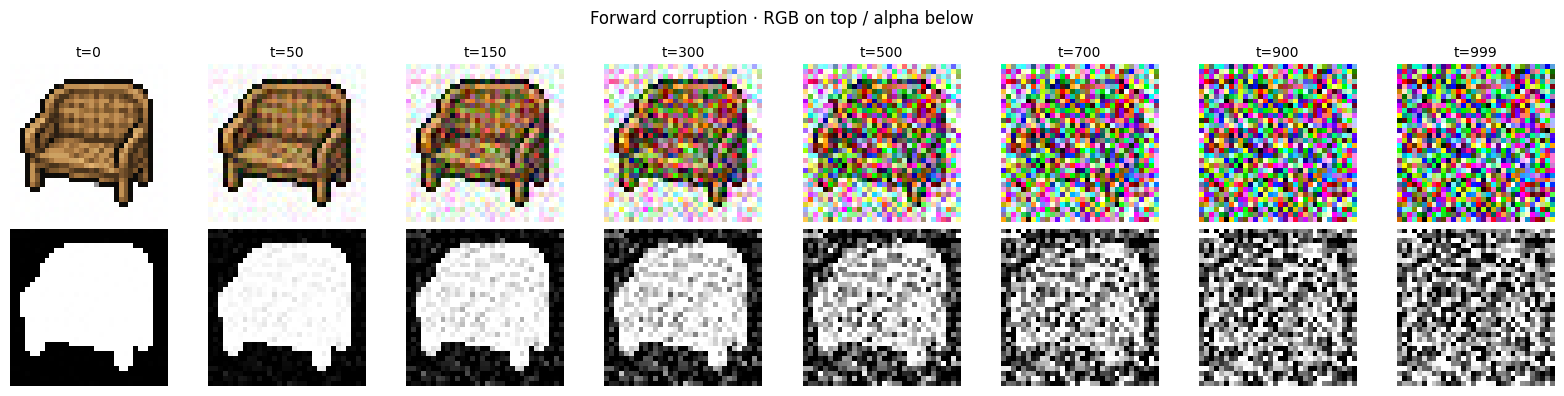

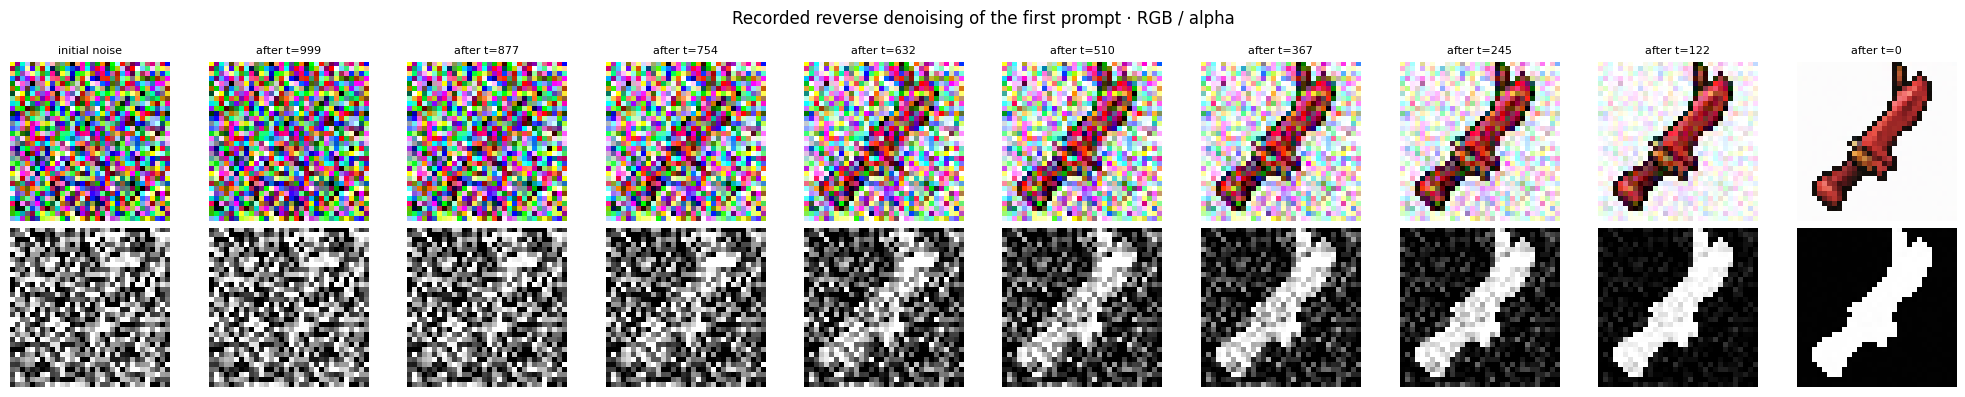

In [ ]:
if not INFERENCE_ONLY:
    clean_example = train_data[0][0].unsqueeze(0).to(device).float() / 127.5 - 1
else:
    clean_example = generated[:1].to(device)
    print('Inference-only: showing forward corruption of a generated sprite.')
forward_generator = torch.Generator(device=device).manual_seed(1234)
fixed_noise = torch.randn(clean_example.shape, generator=forward_generator, device=device)
forward_indices = [0, 50, 150, 300, 500, 700, 900, 999]
fig, axes = plt.subplots(2, len(forward_indices), figsize=(16, 4))
for column, index in enumerate(forward_indices):
    t = torch.tensor([index], device=device)
    noisy = diffusion.q_sample(clean_example, t, fixed_noise)[0].clamp(-1, 1).cpu()
    axes[0, column].imshow(((noisy[:3] + 1) / 2).permute(1, 2, 0), interpolation='nearest')
    axes[1, column].imshow((noisy[3] + 1) / 2, cmap='gray', vmin=0, vmax=1, interpolation='nearest')
    axes[0, column].set_title(f't={index}', fontsize=10)
for ax in axes.flat:
    ax.axis('off')
fig.suptitle('Forward corruption · RGB on top / alpha below')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, len(reverse_frames), figsize=(2 * len(reverse_frames), 4))
for column, (label, frame) in enumerate(reverse_frames):
    image = frame[0].clamp(-1, 1)
    axes[0, column].imshow(((image[:3] + 1) / 2).permute(1, 2, 0), interpolation='nearest')
    axes[1, column].imshow((image[3] + 1) / 2, cmap='gray', vmin=0, vmax=1, interpolation='nearest')
    axes[0, column].set_title(label, fontsize=8)
for ax in axes.flat:
    ax.axis('off')
fig.suptitle('Recorded reverse denoising of the first prompt · RGB / alpha')
plt.tight_layout()
plt.show()

## 15. Export sprites and an inference checkpoint

Native files are 32×32 RGBA. A separate nearest-neighbor enlargement is useful
for viewing. Alpha thresholding is optional postprocessing, not part of the
training loss. The inference checkpoint contains the selected EMA weights and
architecture/text/schedule settings; the larger resume payload also contains
AdamW state, raw weights, RNG and cursor.

To generate after a Colab reset: set `INFERENCE_ONLY=True`, `RESUME=True`,
`SAVE_TO_HF=True`, and the saved `HF_BUCKET` / `RUN_NAME`; run all cells. Dataset
preparation and training will be skipped, and saved architecture/text settings
are restored before generation. To resume training instead, keep
`INFERENCE_ONLY=False`, keep compatible settings, and increase `EPOCHS` as needed.

In [ ]:
THRESHOLD_EXPORTED_ALPHA = True
sprite_dir = OUTPUT_DIR / 'sprites'
sprite_dir.mkdir(exist_ok=True)
for i, image in enumerate(generated):
    native = tensor_to_rgba(image, threshold_alpha=THRESHOLD_EXPORTED_ALPHA)
    native.save(sprite_dir / f'sprite_{i:03d}.png')
    native.resize((256, 256), Image.Resampling.NEAREST).save(sprite_dir / f'sprite_{i:03d}_8x.png')
(sprite_dir / 'prompts.json').write_text(json.dumps(dict(prompts=expanded_prompts, seed=GENERATION_SEED,
    guidance=GUIDANCE_SCALE, sampler=SAMPLER, steps=SAMPLING_STEPS, eta=DDIM_ETA), indent=2))
inference_file = OUTPUT_DIR / 'inference-ema.pt'
atomic_torch_save(dict(format_version=1, model=cpu_tree(generation_model.state_dict()),
    model_config=MODEL_CONFIG, diffusion_config=DIFFUSION_CONFIG, provenance=provenance,
    best_val=state['best_val'], global_step=state['global_step']), inference_file)
if store is not None:
    store.upload_file(inference_file, 'inference-ema.pt')
print('Native sprites and enlargements:', sprite_dir)
print('Inference weights:', inference_file)

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...-full-v1/inference-ema.pt:  42%|####2     | 41.7MB / 98.2MB            

Validating                    :           |   0%            

Native sprites and enlargements: /content/pixelart-text-ddpm/rgba-clip-l14-full-v1/sprites
Inference weights: /content/pixelart-text-ddpm/rgba-clip-l14-full-v1/inference-ema.pt


## 16. Publish an educational toy model on Hugging Face

After training or restoring your run, set `PUBLISH_TO_HF=True` below and run this
cell. It creates a **public model repository**, separate from private recovery
Buckets. An empty `PUBLIC_REPO_ID` uses `<your-username>/toy-pixelart-ddpm`.
The card prominently labels the model as an educational toy with unverified
quality. Only inference weights, configuration, and runnable source are uploaded.
The selected weights are copied without changing the live training EMA.

In [ ]:
"""Public inference bundle builder, embedded in the standalone Colab notebook."""
import json
import math
from pathlib import Path


INFERENCE_SCRIPT = '''"""Generate one RGBA sprite from this educational toy model."""
import argparse
import json
from pathlib import Path
import torch
from safetensors.torch import load_file
from transformers import CLIPTokenizerFast, CLIPTextModel
from pixelart_ddpm import TextUNet, Diffusion, encode_text_batch, sample_images, tensor_to_rgba


@torch.no_grad()
def generate(prompt, folder=".", seed=123, steps=50, guidance=4.0):
    folder = Path(folder)
    config = json.loads((folder / "config.json").read_text())
    provenance = config["provenance"]
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    bf16 = device.type == "cuda" and torch.cuda.is_bf16_supported()
    model = TextUNet(**config["model_config"]).to(device).eval().requires_grad_(False)
    model.load_state_dict(load_file(str(folder / "model.safetensors")))
    model.to(memory_format=torch.channels_last)
    tokenizer = CLIPTokenizerFast.from_pretrained(provenance["text_encoder_id"],
        revision=provenance["text_encoder_revision"])
    encoder = CLIPTextModel.from_pretrained(provenance["text_encoder_id"],
        revision=provenance["text_encoder_revision"],
        dtype=torch.bfloat16 if bf16 else torch.float32).to(device).eval().requires_grad_(False)
    def encode(prompts):
        tokens = tokenizer(prompts, padding="max_length", truncation=True,
            max_length=provenance["max_text_length"], return_tensors="pt")
        return encode_text_batch(encoder, tokens["input_ids"], tokens["attention_mask"], device, bf16)
    hidden, mask = encode([prompt])
    null_hidden, null_mask = encode([""])
    images, _ = sample_images(model, Diffusion(**config["diffusion_config"], device=device),
        hidden, mask, null_hidden, null_mask, sampler="ddim", steps=steps,
        guidance=guidance, seed=seed, use_bf16=bf16, progress=True)
    return tensor_to_rgba(images[0], threshold_alpha=False)


if __name__ == "__main__":
    parser = argparse.ArgumentParser(description="Educational toy pixel-art DDPM; quality is unverified.")
    parser.add_argument("prompt")
    parser.add_argument("--folder", default=".")
    parser.add_argument("--output", default="sprite.png")
    parser.add_argument("--seed", type=int, default=123)
    parser.add_argument("--steps", type=int, default=50)
    parser.add_argument("--guidance", type=float, default=4.0)
    args = parser.parse_args()
    generate(args.prompt, args.folder, args.seed, args.steps, args.guidance).save(args.output)
    print("Saved", args.output)
'''


def prepare_public_bundle(folder, model, model_config, diffusion_config, provenance,
                          training_state, weight_selection, core_source, repo_id, run_name):
    """Write only inference artifacts; leave the live model and training EMA intact."""
    from safetensors.torch import save_file

    folder = Path(folder)
    folder.mkdir(parents=True, exist_ok=True)
    tensors = {key: value.detach().cpu().contiguous().clone()
               for key, value in model.state_dict().items()}
    save_file(tensors, str(folder / 'model.safetensors'))
    best_val = float(training_state['best_val'])
    config = dict(format_version=1, model_config=model_config,
                  diffusion_config=diffusion_config, provenance=provenance,
                  weight_selection=weight_selection, run_name=run_name,
                  global_step=int(training_state['global_step']),
                  best_validation_noise_mse=best_val if math.isfinite(best_val) else None)
    (folder / 'config.json').write_text(json.dumps(config, indent=2, allow_nan=False) + '\n')
    (folder / 'pixelart_ddpm.py').write_text(core_source)
    (folder / 'generate.py').write_text(INFERENCE_SCRIPT)
    (folder / 'requirements.txt').write_text(
        'torch>=2.4\nnumpy\nPillow>=10\ntransformers>=5.0,<6\n'
        'huggingface_hub>=1.25.1,<2\nsafetensors>=0.4\ntqdm\n')
    card = f'''---
language: en
pipeline_tag: text-to-image
library_name: pytorch
tags:
- diffusion
- pixel-art
- toy-model
- educational
datasets:
- {provenance['dataset_id']}
---

# Pixel-art DDPM — educational toy model

**This is a toy model for learning and experimentation. It is not a production
image generator. Sample quality and prompt adherence are unverified and may be
poor; outputs can be noisy, malformed, or unrelated to the prompt.**

## Model

A custom PyTorch text-conditioned U-Net trained from scratch to predict diffusion
noise for native 32×32 RGBA sprites. The frozen text encoder is
`{provenance['text_encoder_id']}` (revision `{provenance['text_encoder_revision']}`).
There is no pretrained image generator or VAE. This repository uses custom
sampling code; it is not a Diffusers pipeline or hosted inference endpoint.
CLIP weights are downloaded separately on first use.

Training data: [{provenance['dataset_id']}](https://huggingface.co/datasets/{provenance['dataset_id']}),
revision `{provenance['dataset_revision']}`. The synthetic dataset may contain
caption errors and pixel-grid artifacts. Inspect its card for provenance and terms.

## Export details

- Run: `{run_name}`
- Completed optimizer steps at export: {config['global_step']}
- Exported weights: **{weight_selection}**
- Best recorded validation noise MSE: {config['best_validation_noise_mse']}

The step count describes the training run at export; a best EMA may come from
an earlier step. Validation noise MSE does not measure visual quality or prompt
accuracy. No benchmark, production suitability, or training convergence is claimed.
Architecture, diffusion settings, source revisions, and recorded package versions
are in `config.json`. Optimizer state and private resume checkpoints are excluded.

## Generate one image

```bash
hf download {repo_id} --local-dir toy-pixelart
cd toy-pixelart
pip install -r requirements.txt
python generate.py "pixel art icon of a purple dragon" --output sprite.png
```

Install `huggingface_hub` first if the `hf` command is unavailable. A GPU is
recommended; CPU generation can be slow. Output is an unthresholded RGBA PNG.
Try `--seed 456`, `--steps 100`, or `--guidance 3.0` to explore behavior.

## Limitations and intended use

Intended for education, inspecting diffusion, and small personal experiments.
Not evaluated for dependable asset creation, safety, fairness, or broad prompt
coverage. It may reproduce training-data patterns. No license grant is asserted
by this export; review applicable model, code, and dataset terms before reuse.
'''
    (folder / 'README.md').write_text(card)
    return ['model.safetensors', 'config.json', 'pixelart_ddpm.py',
            'generate.py', 'requirements.txt', 'README.md']


PUBLIC_CORE_SOURCE = '"""Explicit PyTorch components embedded in pixelart_text_ddpm.ipynb.\n\nThis file is for maintenance and CPU checks. The Colab notebook is standalone.\n"""\n# %% imports\nimport copy\nimport hashlib\nimport json\nimport math\nimport os\nimport random\nimport time\nfrom contextlib import nullcontext\nfrom pathlib import Path\n\nimport numpy as np\nfrom PIL import Image\nimport torch\nfrom torch import nn\nfrom torch.nn import functional as F\nfrom torch.utils.data import Dataset, DataLoader, Sampler\nfrom torch.utils.checkpoint import checkpoint\n\n\ndef seed_everything(seed):\n    random.seed(seed)\n    np.random.seed(seed)\n    torch.manual_seed(seed)\n    if torch.cuda.is_available():\n        torch.cuda.manual_seed_all(seed)\n\n\ndef digest(value):\n    return hashlib.sha256(json.dumps(value, sort_keys=True, ensure_ascii=False).encode()).hexdigest()\n\n\ndef file_sha256(path):\n    h = hashlib.sha256()\n    with open(path, \'rb\') as handle:\n        for chunk in iter(lambda: handle.read(8 << 20), b\'\'):\n            h.update(chunk)\n    return h.hexdigest()\n\n\ndef amp_context(device, enabled=True):\n    return torch.autocast(\'cuda\', dtype=torch.bfloat16) if enabled and device.type == \'cuda\' else nullcontext()\n\n\n# %% architecture\nclass TimeEmbedding(nn.Module):\n    def __init__(self, base=64, dim=256):\n        super().__init__()\n        self.base = base\n        self.mlp = nn.Sequential(nn.Linear(base, dim), nn.SiLU(), nn.Linear(dim, dim))\n\n    def forward(self, t):\n        half = self.base // 2\n        frequencies = torch.exp(-math.log(10000) * torch.arange(half, device=t.device) / (half - 1))\n        angles = t.float()[:, None] * frequencies[None, :]\n        return self.mlp(torch.cat([angles.cos(), angles.sin()], dim=-1))\n\n\nclass ResBlock(nn.Module):\n    """Pre-normalized residual convolutions; time controls scale and shift."""\n    def __init__(self, cin, cout, time_dim=256, dropout=0.1):\n        super().__init__()\n        self.norm1 = nn.GroupNorm(8, cin)\n        self.conv1 = nn.Conv2d(cin, cout, 3, padding=1)\n        self.time = nn.Sequential(nn.SiLU(), nn.Linear(time_dim, 2 * cout))\n        self.norm2 = nn.GroupNorm(8, cout)\n        self.dropout = nn.Dropout(dropout)\n        self.conv2 = nn.Conv2d(cout, cout, 3, padding=1)\n        self.skip = nn.Identity() if cin == cout else nn.Conv2d(cin, cout, 1)\n\n    def forward(self, x, time_emb):\n        h = self.conv1(F.silu(self.norm1(x)))\n        scale, shift = self.time(time_emb).chunk(2, dim=1)\n        h = self.norm2(h) * (1 + scale[:, :, None, None]) + shift[:, :, None, None]\n        h = self.conv2(self.dropout(F.silu(h)))\n        return self.skip(x) + h\n\n\nclass CrossAttention(nn.Module):\n    """Spatial queries attend to valid text tokens; no pretrained image layers."""\n    def __init__(self, channels, context_dim=256, head_dim=64):\n        super().__init__()\n        assert channels % head_dim == 0\n        self.heads = channels // head_dim\n        self.norm = nn.GroupNorm(8, channels)\n        self.q = nn.Linear(channels, channels, bias=False)\n        self.k = nn.Linear(context_dim, channels, bias=False)\n        self.v = nn.Linear(context_dim, channels, bias=False)\n        self.out = nn.Linear(channels, channels)\n        self.ff_norm = nn.LayerNorm(channels)\n        self.ff = nn.Sequential(nn.Linear(channels, channels), nn.GELU(),\n                                nn.Linear(channels, channels))\n\n    def forward(self, x, context, mask):\n        b, c, h, w = x.shape\n        tokens = self.norm(x).flatten(2).transpose(1, 2)\n        def heads(value):\n            return value.reshape(b, -1, self.heads, c // self.heads).transpose(1, 2)\n        q, k, v = heads(self.q(tokens)), heads(self.k(context)), heads(self.v(context))\n        # In SDPA boolean masks, True means a token is allowed to participate.\n        attended = F.scaled_dot_product_attention(q, k, v, attn_mask=mask[:, None, None, :])\n        attended = attended.transpose(1, 2).reshape(b, h * w, c)\n        tokens = x.flatten(2).transpose(1, 2) + self.out(attended)\n        tokens = tokens + self.ff(self.ff_norm(tokens))\n        return tokens.transpose(1, 2).reshape(b, c, h, w)\n\n\nclass ConditionedBlock(nn.Module):\n    def __init__(self, cin, cout, time_dim, dropout, attention, context_dim=256, head_dim=64):\n        super().__init__()\n        self.res = ResBlock(cin, cout, time_dim, dropout)\n        self.attn = CrossAttention(cout, context_dim, head_dim) if attention else None\n\n    def forward(self, x, time_emb, context, mask):\n        x = self.res(x, time_emb)\n        return self.attn(x, context, mask) if self.attn is not None else x\n\n\nclass TextUNet(nn.Module):\n    def __init__(self, in_channels=4, base=64, multipliers=(1, 2, 3, 4),\n                 num_res_blocks=2, text_dim=768, context_dim=256,\n                 dropout=0.1, gradient_checkpointing=False, head_dim=64):\n        super().__init__()\n        self.gradient_checkpointing = gradient_checkpointing\n        self.time = TimeEmbedding(base, base * 4)\n        self.text_projection = nn.Sequential(nn.LayerNorm(text_dim), nn.Linear(text_dim, context_dim))\n        self.input = nn.Conv2d(in_channels, base, 3, padding=1)\n        self.encoder = nn.ModuleList()\n        self.downsamples = nn.ModuleList()\n        skip_channels = [base]\n        current, resolution = base, 32\n        for level, multiplier in enumerate(multipliers):\n            channels = base * multiplier\n            blocks = nn.ModuleList()\n            for _ in range(num_res_blocks):\n                blocks.append(ConditionedBlock(current, channels, base * 4, dropout,\n                                               resolution in (8, 4), context_dim, head_dim))\n                current = channels\n                skip_channels.append(current)\n            self.encoder.append(blocks)\n            if level < len(multipliers) - 1:\n                self.downsamples.append(nn.Conv2d(current, current, 3, stride=2, padding=1))\n                skip_channels.append(current)\n                resolution //= 2\n        self.middle1 = ConditionedBlock(current, current, base * 4, dropout, True, context_dim, head_dim)\n        self.middle2 = ResBlock(current, current, base * 4, dropout)\n        self.decoder = nn.ModuleList()\n        self.upsamples = nn.ModuleList()\n        for level in reversed(range(len(multipliers))):\n            channels = base * multipliers[level]\n            blocks = nn.ModuleList()\n            for _ in range(num_res_blocks + 1):\n                blocks.append(ConditionedBlock(current + skip_channels.pop(), channels, base * 4,\n                                               dropout, resolution in (8, 4), context_dim, head_dim))\n                current = channels\n            self.decoder.append(blocks)\n            if level > 0:\n                self.upsamples.append(nn.Conv2d(current, current, 3, padding=1))\n                resolution *= 2\n        assert not skip_channels\n        self.out_norm = nn.GroupNorm(8, current)\n        self.output = nn.Conv2d(current, in_channels, 3, padding=1)\n        # Start with an almost uninformative prediction; gradients reach all layers.\n        nn.init.normal_(self.output.weight, std=0.01)\n        nn.init.zeros_(self.output.bias)\n\n    def run_block(self, block, *args):\n        if self.gradient_checkpointing and self.training and torch.is_grad_enabled():\n            return checkpoint(block, *args, use_reentrant=False)\n        return block(*args)\n\n    def forward(self, x, timesteps, text_hidden, text_mask):\n        time_emb = self.time(timesteps)\n        context = self.text_projection(text_hidden)\n        h = self.input(x)\n        skips = [h]\n        for level, blocks in enumerate(self.encoder):\n            for block in blocks:\n                h = self.run_block(block, h, time_emb, context, text_mask)\n                skips.append(h)\n            if level < len(self.downsamples):\n                h = self.downsamples[level](h)\n                skips.append(h)\n        h = self.run_block(self.middle1, h, time_emb, context, text_mask)\n        h = self.run_block(self.middle2, h, time_emb)\n        for level, blocks in enumerate(self.decoder):\n            for block in blocks:\n                h = torch.cat([h, skips.pop()], dim=1)\n                h = self.run_block(block, h, time_emb, context, text_mask)\n            if level < len(self.upsamples):\n                h = self.upsamples[level](F.interpolate(h, scale_factor=2, mode=\'nearest\'))\n        return self.output(F.silu(self.out_norm(h)))\n\n\nclass EMA:\n    def __init__(self, model, decay=0.9999):\n        self.model = copy.deepcopy(model).eval().requires_grad_(False)\n        self.decay = decay\n        self.updates = 0\n\n    @torch.no_grad()\n    def update(self, model):\n        self.updates += 1\n        # Warm up averaging so a young EMA does not retain initial random weights.\n        decay = min(self.decay, (1 + self.updates) / (10 + self.updates))\n        for target, source in zip(self.model.parameters(), model.parameters()):\n            target.lerp_(source.detach(), 1 - decay)\n        for target, source in zip(self.model.buffers(), model.buffers()):\n            target.copy_(source)\n\n\n# %% diffusion\nclass Diffusion:\n    def __init__(self, timesteps=1000, device=\'cpu\', cosine_s=0.008):\n        self.timesteps = timesteps\n        self.device = torch.device(device)\n        grid = torch.linspace(0, timesteps, timesteps + 1, dtype=torch.float64)\n        f = torch.cos(((grid / timesteps + cosine_s) / (1 + cosine_s)) * math.pi / 2).square()\n        cumulative = f / f[0]\n        self.betas = (1 - cumulative[1:] / cumulative[:-1]).clamp(max=0.999).float().to(device)\n        self.alphas = 1 - self.betas\n        self.alpha_bars = self.alphas.cumprod(0)\n\n    @staticmethod\n    def extract(array, t, ndim=4):\n        return array[t].reshape(-1, *([1] * (ndim - 1)))\n\n    def q_sample(self, clean, t, noise):\n        a = self.extract(self.alpha_bars, t)\n        return a.sqrt() * clean.float() + (1 - a).sqrt() * noise.float()\n\n    def predict_clean(self, noisy, t, predicted_noise):\n        a = self.extract(self.alpha_bars, t)\n        return (noisy.float() - (1 - a).sqrt() * predicted_noise.float()) / a.sqrt()\n\n    def ddpm_step(self, noisy, t, predicted_noise, noise, previous_t=None):\n        """An ancestral DDPM step on the full or correctly respaced schedule."""\n        previous_t = t - 1 if previous_t is None else previous_t\n        a = self.extract(self.alpha_bars, t)\n        previous = self.extract(self.alpha_bars, previous_t.clamp(min=0))\n        previous = torch.where((previous_t < 0)[:, None, None, None], torch.ones_like(previous), previous)\n        alpha = a / previous\n        beta = 1 - alpha\n        clean = self.predict_clean(noisy, t, predicted_noise).clamp(-1, 1)\n        mean = beta * previous.sqrt() / (1 - a) * clean\n        mean = mean + (1 - previous) * alpha.sqrt() / (1 - a) * noisy\n        variance = beta * (1 - previous) / (1 - a)\n        nonzero = (previous_t >= 0)[:, None, None, None]\n        return mean + nonzero * variance.clamp(min=0).sqrt() * noise\n\n    def ddim_step(self, noisy, t, previous_t, predicted_noise, noise, eta=0.0):\n        """A possibly non-adjacent DDIM step; previous_t = -1 means clean data."""\n        if not 0 <= eta <= 1:\n            raise ValueError(\'DDIM eta must be between 0 and 1.\')\n        a = self.extract(self.alpha_bars, t)\n        previous = self.extract(self.alpha_bars, previous_t.clamp(min=0))\n        previous = torch.where((previous_t < 0)[:, None, None, None], torch.ones_like(previous), previous)\n        clean = self.predict_clean(noisy, t, predicted_noise).clamp(-1, 1)\n        # Recompute epsilon after clipping x0 so the DDIM direction is consistent.\n        corrected_noise = (noisy - a.sqrt() * clean) / (1 - a).sqrt()\n        sigma = eta * (((1 - previous) / (1 - a)) * (1 - a / previous)).clamp(min=0).sqrt()\n        direction = (1 - previous - sigma.square()).clamp(min=0).sqrt() * corrected_noise\n        return previous.sqrt() * clean + direction + sigma * noise\n\n\ndef conditioning_dropout(hidden, mask, null_hidden, null_mask, probability=0.1):\n    drop = torch.rand(hidden.shape[0], device=hidden.device) < probability\n    hidden = torch.where(drop[:, None, None], null_hidden.expand_as(hidden), hidden)\n    mask = torch.where(drop[:, None], null_mask.expand_as(mask), mask)\n    return hidden, mask\n\n\n@torch.no_grad()\ndef sample_images(model, diffusion, hidden, mask, null_hidden, null_mask,\n                  sampler=\'ddim\', steps=50, guidance=4.0, seed=42,\n                  eta=0.0, channels=4, use_bf16=True, progress=False, frames=9):\n    """Both samplers support a respaced grid; DDPM recomputes its effective betas."""\n    if sampler not in (\'ddpm\', \'ddim\'):\n        raise ValueError(\'sampler must be ddpm or ddim\')\n    if not 2 <= steps <= diffusion.timesteps:\n        raise ValueError(\'steps must be between 2 and the number of diffusion timesteps.\')\n    was_training = model.training\n    model.eval()\n    device = next(model.parameters()).device\n    gen = torch.Generator(device=device).manual_seed(seed)\n    b = hidden.shape[0]\n    x = torch.randn((b, channels, 32, 32), generator=gen, device=device)\n    indices = torch.linspace(diffusion.timesteps - 1, 0, steps, device=device).round().long()\n    record_at = set(np.linspace(0, steps - 1, min(frames, steps)).round().astype(int).tolist())\n    trajectory = [(\'initial noise\', x[:1].detach().cpu())]\n    iterator = enumerate(indices.tolist())\n    if progress:\n        from tqdm.auto import tqdm\n        iterator = tqdm(iterator, total=steps, desc=f\'{sampler.upper()} sampling\')\n    try:\n        for i, index in iterator:\n            t = torch.full((b,), index, device=device, dtype=torch.long)\n            with amp_context(device, use_bf16):\n                if guidance == 1.0:\n                    predicted = model(x, t, hidden, mask)\n                else:\n                    # Sequential CFG halves the peak batch size versus concatenating.\n                    unconditioned = model(x, t, null_hidden.expand(b, -1, -1), null_mask.expand(b, -1))\n                    conditioned = model(x, t, hidden, mask)\n                    predicted = unconditioned + guidance * (conditioned - unconditioned)\n            fresh_noise = torch.randn(x.shape, device=device, generator=gen)\n            prev = indices[i + 1].item() if i + 1 < steps else -1\n            previous_t = torch.full_like(t, prev)\n            if sampler == \'ddpm\':\n                x = diffusion.ddpm_step(x, t, predicted.float(), fresh_noise, previous_t)\n            else:\n                x = diffusion.ddim_step(x, t, previous_t, predicted.float(), fresh_noise, eta)\n            if not torch.isfinite(x).all():\n                raise FloatingPointError(f\'Non-finite sample at timestep {index}.\')\n            if i in record_at:\n                trajectory.append((f\'after t={index}\', x[:1].detach().cpu()))\n    finally:\n        model.train(was_training)\n    return x.clamp(-1, 1).cpu(), trajectory\n\n\n# %% data_helpers\ndef canonical_rgba(image):\n    if not isinstance(image, Image.Image):\n        raise TypeError(\'Expected a decoded PIL image; inspect the dataset schema.\')\n    if image.size != (32, 32):\n        raise ValueError(f\'Expected native 32x32 sprites, got {image.size}.\')\n    rgba = np.array(image.convert(\'RGBA\'), dtype=np.uint8, copy=True)\n    # Hidden RGB values have no appearance. Canonicalize them to avoid learning junk.\n    rgba[rgba[:, :, 3] == 0, :3] = 255\n    return np.ascontiguousarray(rgba.transpose(2, 0, 1))\n\n\ndef inspect_schema(source, image_column=\'image\', caption_column=\'caption\'):\n    if \'train\' not in source:\n        raise ValueError(\'Dataset must contain a train split.\')\n    report = {}\n    for split, data in source.items():\n        print(f\'{split}: {len(data):,} rows; features: {data.features}\')\n        if image_column not in data.column_names or caption_column not in data.column_names:\n            raise ValueError(f\'{split} is missing {image_column!r} or {caption_column!r}.\')\n        row = data[0]\n        image, caption = row[image_column], row[caption_column]\n        if not isinstance(caption, str) or not caption.strip():\n            raise ValueError(\'The selected caption column does not contain nonempty text.\')\n        canonical_rgba(image)\n        report[split] = dict(rows=len(data), columns=data.column_names,\n                             mode=image.mode, size=list(image.size), example_caption=caption)\n        print(\'First image:\', image.mode, image.size, \'| caption:\', repr(caption))\n    return report\n\n\ndef prepare_pairs(source, folder, data_config, tokenizer):\n    """Schema inspection must precede this call. Cache uint8 pixels, not CLIP states."""\n    folder = Path(folder)\n    folder.mkdir(parents=True, exist_ok=True)\n    manifest_path = folder / \'manifest.json\'\n    if manifest_path.exists():\n        manifest = json.loads(manifest_path.read_text())\n        if manifest[\'data_config\'] != data_config:\n            raise ValueError(\'Prepared data config mismatch.\')\n        for filename, expected in manifest[\'sha256\'].items():\n            if file_sha256(folder / filename) != expected:\n                raise ValueError(f\'Prepared data checksum mismatch: {filename}\')\n        return manifest\n    from tqdm.auto import tqdm\n    seed = data_config[\'seed\']\n    # Prefer the published general validation set. The fallback groups captions.\n    official_val = \'val\' in source\n    if official_val:\n        val_source = source[\'val\']\n        val_candidates = np.random.default_rng(seed + 1).permutation(len(val_source)).tolist()\n        train_candidates = np.random.default_rng(seed).permutation(len(source[\'train\'])).tolist()\n        val_split_name = \'val\'\n    else:\n        train_candidates, val_candidates = [], []\n        for i, caption in enumerate(source[\'train\'][data_config[\'caption_column\']]):\n            key = \' \'.join(str(caption).split())\n            is_val = int(digest([seed, key])[:8], 16) % 100 < 5\n            (val_candidates if is_val else train_candidates).append(i)\n        np.random.default_rng(seed).shuffle(train_candidates)\n        np.random.default_rng(seed + 1).shuffle(val_candidates)\n        val_source = source[\'train\']\n        val_split_name = \'train (caption-grouped holdout)\'\n    sources = {\'train\': source[\'train\'], \'val\': val_source}\n    candidates = {\'train\': train_candidates, \'val\': val_candidates}\n    seen_images, metadata, sha256 = set(), {}, {}\n    # Reserve validation images first; exact train/val image duplicates are removed.\n    for split in (\'val\', \'train\'):\n        requested = data_config[\'max_val_images\' if split == \'val\' else \'max_train_images\']\n        capacity = min(requested, len(candidates[split])) if requested is not None else len(candidates[split])\n        if capacity < 1:\n            raise ValueError(f\'Empty {split} candidates.\')\n        pixels = np.lib.format.open_memmap(folder / f\'{split}_images.npy\', mode=\'w+\',\n                                          dtype=np.uint8, shape=(capacity, 4, 32, 32))\n        captions, rows, skipped = [], [], {}\n        for index in tqdm(candidates[split], desc=f\'Prepare {split}\', leave=False):\n            row = sources[split][index]\n            flags = row.get(\'flags\') or []\n            if any(flag in flags for flag in data_config[\'reject_flags\']):\n                skipped[\'quality_flag\'] = skipped.get(\'quality_flag\', 0) + 1\n                continue\n            raw_caption = row[data_config[\'caption_column\']]\n            if not isinstance(raw_caption, str) or not raw_caption.strip():\n                skipped[\'missing_caption\'] = skipped.get(\'missing_caption\', 0) + 1\n                continue\n            image = canonical_rgba(row[data_config[\'image_column\']])\n            image_hash = hashlib.sha256(image.tobytes()).hexdigest()\n            if image_hash in seen_images:\n                skipped[\'duplicate_image\'] = skipped.get(\'duplicate_image\', 0) + 1\n                continue\n            seen_images.add(image_hash)\n            pixels[len(captions)] = image\n            captions.append(\' \'.join(raw_caption.split()))\n            rows.append([int(index), image_hash])\n            if len(captions) == capacity:\n                break\n        pixels.flush()\n        del pixels\n        if not captions:\n            raise ValueError(f\'No accepted {split} images.\')\n        if requested is not None and len(captions) < min(requested, len(candidates[split])):\n            raise ValueError(f\'Cannot fill {split}: requested {requested}, accepted {len(captions)}. Reduce size or filters.\')\n        ids, masks = [], []\n        for start in range(0, len(captions), 512):\n            encoded = tokenizer(captions[start:start + 512], padding=\'max_length\', truncation=True,\n                                max_length=data_config[\'max_text_length\'], return_tensors=\'np\')\n            ids.append(encoded[\'input_ids\'].astype(np.int32))\n            masks.append(encoded[\'attention_mask\'].astype(np.bool_))\n        np.save(folder / f\'{split}_ids.npy\', np.concatenate(ids))\n        np.save(folder / f\'{split}_masks.npy\', np.concatenate(masks))\n        (folder / f\'{split}_captions.json\').write_text(json.dumps(captions, ensure_ascii=False))\n        metadata[split] = dict(count=len(captions), selected_rows=rows, skipped=skipped,\n                               source_split=val_split_name if split == \'val\' else \'train\')\n        for suffix in (\'images.npy\', \'ids.npy\', \'masks.npy\', \'captions.json\'):\n            filename = f\'{split}_{suffix}\'\n            sha256[filename] = file_sha256(folder / filename)\n        print(split, \'accepted:\', len(captions), \'| skipped:\', skipped)\n    identity = digest(dict(data_config=data_config, metadata=metadata, sha256=sha256))\n    manifest = dict(data_config=data_config, splits=metadata, sha256=sha256, identity=identity)\n    temporary = manifest_path.with_suffix(\'.tmp\')\n    temporary.write_text(json.dumps(manifest, indent=2))\n    temporary.replace(manifest_path)\n    return manifest\n\n\nclass SpritePairs(Dataset):\n    def __init__(self, folder, split, count):\n        folder = Path(folder)\n        self.images = np.load(folder / f\'{split}_images.npy\', mmap_mode=\'r\')[:count]\n        self.ids = np.load(folder / f\'{split}_ids.npy\', mmap_mode=\'r\')[:count]\n        self.masks = np.load(folder / f\'{split}_masks.npy\', mmap_mode=\'r\')[:count]\n\n    def __len__(self):\n        return len(self.images)\n\n    def __getitem__(self, i):\n        # Copy only the requested row; leave the dataset uint8 and memory-mapped.\n        return (torch.from_numpy(self.images[i].copy()),\n                torch.from_numpy(self.ids[i].astype(np.int64)),\n                torch.from_numpy(self.masks[i].copy()))\n\n\nclass EpochBatchSampler(Sampler):\n    """A recoverable permutation: (seed, epoch, next_batch) specifies the cursor."""\n    def __init__(self, size, batch_size, seed, epoch, start_batch=0):\n        self.batch_size = batch_size\n        self.order = torch.randperm(size, generator=torch.Generator().manual_seed(seed + epoch)).tolist()\n        self.start_batch = start_batch\n\n    def __iter__(self):\n        for start in range(self.start_batch * self.batch_size, len(self.order), self.batch_size):\n            yield self.order[start:start + self.batch_size]\n\n    def __len__(self):\n        return max(0, math.ceil(len(self.order) / self.batch_size) - self.start_batch)\n\n\ndef make_train_loader(dataset, batch_size, seed, epoch, next_batch=0, workers=2, pin=False):\n    sampler = EpochBatchSampler(len(dataset), batch_size, seed, epoch, next_batch)\n    kwargs = dict(num_workers=workers, pin_memory=pin,\n                  generator=torch.Generator().manual_seed(seed + epoch + 100000))\n    if workers:\n        kwargs.update(prefetch_factor=2, persistent_workers=False)\n    return DataLoader(dataset, batch_sampler=sampler, **kwargs)\n\n\n# %% recovery\ndef cpu_tree(value):\n    if torch.is_tensor(value):\n        return value.detach().cpu().clone()\n    if isinstance(value, dict):\n        return {k: cpu_tree(v) for k, v in value.items()}\n    if isinstance(value, list):\n        return [cpu_tree(v) for v in value]\n    if isinstance(value, tuple):\n        return tuple(cpu_tree(v) for v in value)\n    return value\n\n\ndef capture_rng():\n    np_state = np.random.get_state()\n    return dict(python=random.getstate(), numpy=[np_state[0], np_state[1].tolist(),\n                np_state[2], np_state[3], np_state[4]], torch=torch.get_rng_state(),\n                cuda=[s.cpu() for s in torch.cuda.get_rng_state_all()] if torch.cuda.is_available() else [])\n\n\ndef restore_rng(state):\n    random.setstate(state[\'python\'])\n    n = state[\'numpy\']\n    np.random.set_state((n[0], np.array(n[1], dtype=np.uint32), n[2], n[3], n[4]))\n    torch.set_rng_state(state[\'torch\'].cpu())\n    if torch.cuda.is_available() and state[\'cuda\']:\n        torch.cuda.set_rng_state_all([s.cpu() for s in state[\'cuda\']])\n\n\ndef atomic_torch_save(value, path):\n    path = Path(path)\n    temporary = path.with_name(path.name + \'.tmp\')\n    torch.save(value, temporary)\n    os.replace(temporary, path)\n\n\nclass BucketStore:\n    """Two payload slots, with a small last-written manifest as the commit point."""\n    def __init__(self, api, bucket, run_name, folder):\n        self.api, self.bucket, self.run_name = api, bucket, run_name\n        self.folder = Path(folder)\n        self.folder.mkdir(parents=True, exist_ok=True)\n        self.current_slot = None\n\n    def remote(self, filename):\n        return f\'{self.run_name}/{filename}\'\n\n    def exists(self):\n        info = list(self.api.get_bucket_paths_info(self.bucket, paths=[self.remote(\'latest.json\')]))\n        return bool(info)\n\n    def upload_file(self, path, name):\n        for attempt in range(3):\n            try:\n                self.api.batch_bucket_files(self.bucket, add=[(str(path), self.remote(name))])\n                return\n            except Exception:\n                if attempt == 2:\n                    raise\n                time.sleep(2 ** attempt)\n\n    def save(self, payload):\n        # Refresh the remote commit point. A prior pointer upload can succeed on\n        # the server even if its response is lost; never rely on a stale slot.\n        if self.exists():\n            pointer = self.folder / \'before-upload-latest.json\'\n            self.api.download_bucket_files(self.bucket, files=[(self.remote(\'latest.json\'), str(pointer))],\n                                           raise_on_missing_files=True)\n            self.current_slot = self.validate_manifest(json.loads(pointer.read_text()))[\'slot\']\n        else:\n            self.current_slot = None\n        slot = \'b\' if self.current_slot == \'a\' else \'a\'\n        name = f\'resume-{slot}.pt\'\n        path = self.folder / name\n        atomic_torch_save(payload, path)\n        manifest = dict(format_version=1, slot=slot, filename=name,\n                        sha256=file_sha256(path), bytes=path.stat().st_size,\n                        step=int(payload[\'state\'][\'global_step\']))\n        # The active slot is never overwritten. A failed upload leaves latest valid.\n        self.upload_file(path, name)\n        pointer = self.folder / \'latest-upload.json\'\n        pointer.write_text(json.dumps(manifest))\n        self.upload_file(pointer, \'latest.json\')\n        self.current_slot = slot\n        (self.folder / \'latest.json\').write_text(json.dumps(manifest))\n        print(f\'Bucket committed step {manifest["step"]}: {self.bucket}/{self.run_name}\')\n\n    def load(self):\n        pointer = self.folder / \'download-latest.json\'\n        self.api.download_bucket_files(self.bucket, files=[(self.remote(\'latest.json\'), str(pointer))],\n                                       raise_on_missing_files=True)\n        manifest = self.validate_manifest(json.loads(pointer.read_text()))\n        path = self.folder / manifest[\'filename\']\n        self.api.download_bucket_files(self.bucket, files=[(self.remote(manifest[\'filename\']), str(path))],\n                                       raise_on_missing_files=True)\n        if path.stat().st_size != manifest[\'bytes\'] or file_sha256(path) != manifest[\'sha256\']:\n            raise ValueError(\'Downloaded checkpoint failed size/SHA-256 verification.\')\n        payload = torch.load(path, map_location=\'cpu\', weights_only=True)\n        self.current_slot = manifest[\'slot\']\n        return payload\n\n    @staticmethod\n    def validate_manifest(manifest):\n        if (manifest.get(\'format_version\') != 1 or manifest.get(\'slot\') not in (\'a\', \'b\')\n                or manifest.get(\'filename\') != f\'resume-{manifest.get("slot")}.pt\'):\n            raise ValueError(\'Unsupported checkpoint manifest.\')\n        return manifest\n\n\ndef new_training_state():\n    return dict(epoch=0, next_batch=0, global_step=0, epoch_loss_sum=0.0,\n                epoch_images=0, best_val=float(\'inf\'), history=[], step_history=[])\n\n\ndef build_payload(model, ema, optimizer, state, best_ema, model_config,\n                  diffusion_config, run_signature, data_manifest, provenance):\n    return dict(format_version=1, model=cpu_tree(model.state_dict()),\n                ema=cpu_tree(ema.model.state_dict()), ema_updates=ema.updates,\n                optimizer=cpu_tree(optimizer.state_dict()), state=copy.deepcopy(state),\n                best_ema=cpu_tree(best_ema), rng=capture_rng(),\n                model_config=model_config, diffusion_config=diffusion_config,\n                run_signature=run_signature, data_manifest=data_manifest,\n                provenance=provenance)\n\n\ndef restore_training(payload, model, ema, optimizer, signature):\n    if payload.get(\'format_version\') != 1 or payload[\'run_signature\'] != signature:\n        raise ValueError(\'Checkpoint/data/training settings differ. Restore the saved settings or use a new run name.\')\n    model.load_state_dict(payload[\'model\'])\n    ema.model.load_state_dict(payload[\'ema\'])\n    ema.updates = payload[\'ema_updates\']\n    optimizer.load_state_dict(payload[\'optimizer\'])\n    restore_rng(payload[\'rng\'])\n    return copy.deepcopy(payload[\'state\']), cpu_tree(payload[\'best_ema\'])\n\n\n# %% training_helpers\n@torch.no_grad()\ndef encode_text_batch(text_encoder, ids, mask, device, use_bf16=True):\n    # no_grad (not inference_mode): trainable cross-attention must save its inputs.\n    with amp_context(device, use_bf16):\n        hidden = text_encoder(input_ids=ids.to(device, non_blocking=True),\n                              attention_mask=mask.to(device, non_blocking=True)).last_hidden_state\n    return hidden.detach(), mask.to(device, dtype=torch.bool, non_blocking=True)\n\n\ndef train_one_batch(model, ema, optimizer, diffusion, images, ids, masks,\n                    text_encoder, null_hidden, null_mask, micro_batch=64,\n                    dropout=0.1, use_bf16=True, grad_clip=1.0):\n    device = next(model.parameters()).device\n    model.train()\n    optimizer.zero_grad(set_to_none=True)\n    batch_size, loss_sum = len(images), 0.0\n    for start in range(0, batch_size, micro_batch):\n        stop = min(start + micro_batch, batch_size)\n        clean = images[start:stop].to(device, dtype=torch.float32, non_blocking=True) / 127.5 - 1\n        clean = clean.contiguous(memory_format=torch.channels_last)\n        hidden, mask = encode_text_batch(text_encoder, ids[start:stop], masks[start:stop], device, use_bf16)\n        hidden, mask = conditioning_dropout(hidden, mask, null_hidden, null_mask, dropout)\n        t = torch.randint(diffusion.timesteps, (len(clean),), device=device)\n        noise = torch.randn_like(clean)\n        noisy = diffusion.q_sample(clean, t, noise)\n        with amp_context(device, use_bf16):\n            prediction = model(noisy, t, hidden, mask)\n        loss = F.mse_loss(prediction.float(), noise)\n        if not torch.isfinite(loss):\n            optimizer.zero_grad(set_to_none=True)\n            raise FloatingPointError(\'Non-finite training loss; no optimizer update was applied.\')\n        (loss * ((stop - start) / batch_size)).backward()\n        loss_sum += loss.detach().item() * (stop - start)\n    norm = nn.utils.clip_grad_norm_(model.parameters(), grad_clip, error_if_nonfinite=True)\n    optimizer.step()\n    ema.update(model)\n    return loss_sum / batch_size, float(norm)\n\n\n@torch.no_grad()\ndef validation_loss(model, diffusion, loader, text_encoder, device, use_bf16=True, seed=31415):\n    model.eval()\n    gen = torch.Generator(device=device).manual_seed(seed)\n    total, count = 0.0, 0\n    for images, ids, masks in loader:\n        clean = images.to(device, dtype=torch.float32, non_blocking=True) / 127.5 - 1\n        hidden, mask = encode_text_batch(text_encoder, ids, masks, device, use_bf16)\n        t = torch.randint(diffusion.timesteps, (len(clean),), generator=gen, device=device)\n        noise = torch.randn(clean.shape, generator=gen, device=device)\n        with amp_context(device, use_bf16):\n            prediction = model(diffusion.q_sample(clean, t, noise), t, hidden, mask)\n        loss = F.mse_loss(prediction.float(), noise)\n        if not torch.isfinite(loss):\n            raise FloatingPointError(\'Non-finite validation loss.\')\n        total += loss.item() * len(clean)\n        count += len(clean)\n    if not count:\n        raise ValueError(\'Validation set is empty.\')\n    return total / count\n\n\n# %% visualization\ndef tensor_to_rgba(image, threshold_alpha=False):\n    rgba = ((image.detach().cpu().float().clamp(-1, 1) + 1) * 127.5).round().byte()\n    rgba = rgba.permute(1, 2, 0).numpy().copy()\n    if threshold_alpha:\n        rgba[:, :, 3] = np.where(rgba[:, :, 3] >= 128, 255, 0)\n        rgba[rgba[:, :, 3] == 0, :3] = 255\n    return Image.fromarray(rgba)\n\n\ndef checkerboard(image, scale=6):\n    rgba = image.convert(\'RGBA\')\n    yy, xx = np.indices((rgba.height, rgba.width))\n    values = np.where((xx // 4 + yy // 4) % 2, 205, 245).astype(np.uint8)\n    bg = Image.fromarray(np.repeat(values[:, :, None], 3, axis=2)).convert(\'RGBA\')\n    result = Image.alpha_composite(bg, rgba).convert(\'RGB\')\n    return result.resize((rgba.width * scale, rgba.height * scale), Image.Resampling.NEAREST)\n\n\ndef show_sprites(images, labels=None, columns=4, threshold_alpha=False, title=None):\n    import matplotlib.pyplot as plt\n    rows = math.ceil(len(images) / columns)\n    fig, axes = plt.subplots(rows, columns, figsize=(columns * 2.5, rows * 2.7), squeeze=False)\n    for ax in axes.flat:\n        ax.axis(\'off\')\n    for i, image in enumerate(images):\n        axes.flat[i].imshow(checkerboard(tensor_to_rgba(image, threshold_alpha)), interpolation=\'nearest\')\n        if labels:\n            axes.flat[i].set_title(labels[i], fontsize=9, wrap=True)\n    if title:\n        fig.suptitle(title)\n    plt.tight_layout()\n    plt.show()\n'

PUBLISH_TO_HF = False            # Set True to publish publicly, then run this cell.
PUBLIC_REPO_ID = ""             # Empty -> <your-username>/toy-pixelart-ddpm.
PUBLIC_WEIGHTS = "best"         # "best" or "latest".

if PUBLISH_TO_HF:
    from huggingface_hub import HfApi, get_token, notebook_login
    public_api = globals().get('api')
    if public_api is None:
        public_token = get_token()
        if not public_token:
            try:
                from google.colab import userdata
                public_token = userdata.get('HF_TOKEN')
            except Exception:
                pass
        if not public_token:
            notebook_login()
            public_token = get_token()
        public_api = HfApi(token=public_token)
    public_repo = PUBLIC_REPO_ID or f"{public_api.whoami()['name']}/toy-pixelart-ddpm"
    if PUBLIC_WEIGHTS == 'best' and best_ema is not None:
        public_state, selected = best_ema, 'best validated EMA'
    elif PUBLIC_WEIGHTS in ('best', 'latest'):
        public_state, selected = ema.model.state_dict(), 'latest EMA'
    else:
        raise ValueError('PUBLIC_WEIGHTS must be best or latest.')
    public_model = TextUNet(**MODEL_CONFIG).eval().requires_grad_(False)
    public_model.load_state_dict(public_state)
    public_folder = OUTPUT_DIR / 'public-model'
    public_files = prepare_public_bundle(public_folder, public_model, MODEL_CONFIG,
        DIFFUSION_CONFIG, provenance, state, selected, PUBLIC_CORE_SOURCE, public_repo, RUN_NAME)
    del public_model
    public_api.create_repo(repo_id=public_repo, repo_type='model', private=False, exist_ok=True)
    # create_repo(exist_ok=True) does not change an existing repository's visibility.
    public_api.update_repo_settings(repo_id=public_repo, repo_type='model', private=False)
    public_api.upload_folder(repo_id=public_repo, repo_type='model', folder_path=str(public_folder),
        allow_patterns=public_files, commit_message='Publish educational toy pixel-art DDPM')
    print('Public toy model:', f'https://huggingface.co/{public_repo}')
else:
    print('To publish, set PUBLISH_TO_HF=True and rerun this cell.')

## 17. What to check before a long run

- **Debug succeeds:** shapes match; losses/gradients stay finite; both samplers run;
  Bucket uploads succeed; `RESUME=True` restores the reported update and cursor.
- **Tiny-data diagnostic:** set a new run name, `MAX_TRAIN_IMAGES=64`, more epochs,
  and `MAX_STEPS=None`. Check whether the model can reproduce training prompts.
  This tests the pipeline, not generalization.
- **Full training:** set `MODE="full"`, a new run name, and start with the provided
  64-image logical batch. Use the VRAM probe rather than assuming a batch fits.
- **Evaluate content:** hold seeds fixed and change object/color words; inspect
  whether the outputs follow the prompt. Check unseen prompts separately.
- **Evaluate appearance:** inspect native 32×32 pixels, silhouettes, transparency,
  outlines and color consistency. An enlarged picture can conceal pixel defects.
- **Keep saves durable:** the printed successful Bucket commit is the recovery
  point. Periodic saves can be several hundred MB; shorten intervals for safer
  recovery or lengthen them to reduce upload overhead.

### References and scope

- [Dataset card and known issues](https://huggingface.co/datasets/azyg0s/pixelart-172k)
- [CLIP ViT-L/14 checkpoint](https://huggingface.co/openai/clip-vit-large-patch14)
- [DDPM · Ho et al.](https://arxiv.org/abs/2006.11239)
- [Cosine schedule · Nichol & Dhariwal](https://arxiv.org/abs/2102.09672)
- [DDIM · Song et al.](https://arxiv.org/abs/2010.02502)
- [Classifier-free guidance · Ho & Salimans](https://arxiv.org/abs/2207.12598)
- [Hugging Face Bucket API](https://huggingface.co/docs/huggingface_hub/guides/buckets)

This notebook implements a noise-prediction **DDPM**, not the flow-matching
objective used by the dataset author's Pixelart-50m checkpoint. That pretrained
image generator is never loaded. Package versions and source revisions are saved
for provenance. CPU synthetic checks validate the implementation; full L4
training time, live authenticated Bucket transfers and trained sample quality
must be established by running the notebook.